In [ ]:
# load the botq panel from the drive zip archive
import os
import zipfile
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/Notability/Silver Fund/Copy of BotQ_2026_data.zip"
EXPECTED_BASENAME = "BotQ_2026_data.parquet"

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(f"Could not find the Drive archive: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    matches = [name for name in archive.namelist() if name.rsplit("/", 1)[-1] == EXPECTED_BASENAME]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one {EXPECTED_BASENAME} in the ZIP; found: {matches[:10]}")
    member = matches[0]
    DATA_PATH = archive.extract(member, path="/content")

print(f"Extracted {member} to {DATA_PATH}")
with open(DATA_PATH, "rb") as data_file:
    signature = data_file.read(4)
if signature == b"PAR1":
    df = pd.read_parquet(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH)

print(f"Loaded panel: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Columns: {list(df.columns)}")
display(df.head())

Mounted at /content/drive
Extracted BotQ_data/BotQ_2026_data.parquet to /content/BotQ_data/BotQ_2026_data.parquet


/tmp/ipykernel_1924/3076064289.py:29: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


Loaded panel: 19,129,651 rows × 10 columns
Columns: ['ticker', 'barrid', 'cusip', 'date', 'price', 'historical_beta', 'predicted_beta', 'return', 'specific_risk', 'name']


,ticker,barrid,cusip,date,price,historical_beta,predicted_beta,return,specific_risk,name
0,MDXG,USA06Z1,602496101,2013-07-31,6.26,0.328385,0.343490,-0.1595,55.056916,MIMEDX GROUP INC
1,MDXG,USA06Z1,602496101,2013-08-01,6.32,0.334989,0.353329,0.9585,55.028021,MIMEDX GROUP INC
2,MDXG,USA06Z1,602496101,2013-08-02,6.31,0.330713,0.363624,-0.1582,54.807402,MIMEDX GROUP INC
3,MDXG,USA06Z1,602496101,2013-08-05,6.45,0.324494,0.356596,2.2187,54.766710,MIMEDX GROUP INC
4,MDXG,USA06Z1,602496101,2013-08-06,6.29,0.366323,0.399196,-2.4806,54.692162,MIMEDX GROUP INC


In [ ]:
from IPython.display import display, Markdown
import pandas as pd

# Plain-language guide for the team

display(Markdown(r"""
# Stock strategy project

## The question
Can simple rules based on a stock's recent returns and risk help us build a better portfolio than the broad U.S. stock market?

We use past data to rank stocks each month, buy the highest-ranked group, and see what happened in the following month. We compare the results with **IWV**, an exchange-traded fund (ETF) that tracks the Russell 3000 as a practical market benchmark.

## The signals in everyday language

- **Momentum:** stocks that have done well over the past year may keep doing well. We skip the most recent month in the main version.
- **Low beta:** stocks that have tended to move less when the market moves.
- **Low specific risk (IVOL proxy):** stocks with lower company-specific risk according to the supplied data.
- **Composite:** combine signal ranks so no single signal decides the whole portfolio.
- **Volatility management:** when recent portfolio ups and downs are large, reduce how much we invest; when they are smaller, allow more exposure within a preset limit.

Each month, the main test holds the top 30% of eligible stocks and then rebalances. The added portfolios change one ingredient at a time so we can see what each change does.

## A few terms used in the results

- **Return:** how much the portfolio gained or lost.
- **Volatility:** how much its returns usually jump around. Higher volatility means a bumpier ride.
- **Sharpe ratio:** average return compared with the size of those jumps. Here, a higher value means more return for each unit of volatility; it does not guarantee future performance.
- **Drawdown:** how far the portfolio fell from an earlier high before recovering.
- **Holdout:** a later time period used to judge the strategy after its rules were set.

## How to read this notebook

1. Check the data and the rules used to form portfolios.
2. Compare the basic signals and combinations with the market benchmark.
3. Look at returns, risk, bad periods, trading-cost assumptions, and market exposure.
4. Review the added portfolio versions, which test residual momentum, low IVOL, and changing exposure based on recent volatility.

The research papers listed in the notebook give ideas for these tests. This project uses simplified versions and is **not a full replication** of those papers.

## Important limits

This is a test on the supplied U.S. stock data, not a forecast. IWV is an ETF proxy for the Russell 3000 index. The data do not include a complete historical membership list or all information needed to estimate realistic trading costs. Cost results use assumptions. The added residual-momentum measure is an approximation, and the volatility-management example uses a lagged moving estimate, not a GARCH model.
"""))

coverage = pd.DataFrame({
    "Value": [len(df), df["barrid"].nunique(), pd.to_datetime(df["date"]).min().date(), pd.to_datetime(df["date"]).max().date()]
}, index=["Daily rows", "Unique security IDs", "First date", "Last date"])
display(coverage)



# Stock strategy project

## The question
Can simple rules based on a stock's recent returns and risk help us build a better portfolio than the broad U.S. stock market?

We use past data to rank stocks each month, buy the highest-ranked group, and see what happened in the following month. We compare the results with **IWV**, an exchange-traded fund (ETF) that tracks the Russell 3000 as a practical market benchmark.

## The signals in everyday language

- **Momentum:** stocks that have done well over the past year may keep doing well. We skip the most recent month in the main version.
- **Low beta:** stocks that have tended to move less when the market moves.
- **Low specific risk (IVOL proxy):** stocks with lower company-specific risk according to the supplied data.
- **Composite:** combine signal ranks so no single signal decides the whole portfolio.
- **Volatility management:** when recent portfolio ups and downs are large, reduce how much we invest; when they are smaller, allow more exposure within a preset limit.

Each month, the main test holds the top 30% of eligible stocks and then rebalances. The added portfolios change one ingredient at a time so we can see what each change does.

## A few terms used in the results

- **Return:** how much the portfolio gained or lost.
- **Volatility:** how much its returns usually jump around. Higher volatility means a bumpier ride.
- **Sharpe ratio:** average return compared with the size of those jumps. Here, a higher value means more return for each unit of volatility; it does not guarantee future performance.
- **Drawdown:** how far the portfolio fell from an earlier high before recovering.
- **Holdout:** a later time period used to judge the strategy after its rules were set.

## How to read this notebook

1. Check the data and the rules used to form portfolios.
2. Compare the basic signals and combinations with the market benchmark.
3. Look at returns, risk, bad periods, trading-cost assumptions, and market exposure.
4. Review the added portfolio versions, which test residual momentum, low IVOL, and changing exposure based on recent volatility.

The research papers listed in the notebook give ideas for these tests. This project uses simplified versions and is **not a full replication** of those papers.

## Important limits

This is a test on the supplied U.S. stock data, not a forecast. IWV is an ETF proxy for the Russell 3000 index. The data do not include a complete historical membership list or all information needed to estimate realistic trading costs. Cost results use assumptions. The added residual-momentum measure is an approximation, and the volatility-management example uses a lagged moving estimate, not a GARCH model.


,Value
Daily rows,19129651
Unique security IDs,9162
First date,2000-01-03
Last date,2025-10-16


# PART I — Original Signals: Low Beta, Momentum & Specific Risk (IVOL proxy)

The original portfolio tests, benchmark comparisons, extensions, and recap are grouped below.

## Holdout performance | January 2011 onward

,Months,CAGR,Volatility,Sharpe (rf=0),Max drawdown,Beta,Active CAGR,Tracking error,Information ratio
Strategy,,,,,,,,,
Russell 3000 proxy (IWV),177,13.4%,14.6%,0.94,-24.6%,1.00,+0.0%,0.0%,nan
Momentum,177,2.4%,17.5%,0.23,-36.8%,1.08,-11.0%,7.6%,-1.29
Low beta,177,0.1%,12.9%,0.07,-32.5%,0.75,-13.4%,7.9%,-1.63
Low specific risk,177,9.3%,15.1%,0.67,-29.6%,0.94,-4.1%,6.3%,-0.58
Composite,177,3.5%,13.2%,0.33,-28.4%,0.81,-10.0%,6.5%,-1.44
Vol-managed momentum,177,-0.1%,13.3%,0.06,-37.9%,0.79,-13.5%,7.2%,-1.80
IWV + MOM overlay,177,15.2%,15.6%,0.99,-22.9%,1.00,+1.8%,5.5%,0.31
IWV + Composite overlay,177,18.2%,15.5%,1.17,-24.6%,0.99,+4.8%,5.6%,0.78


### Development sample | fixed rules, 2001–2010

,Months,CAGR,Volatility,Sharpe (rf=0),Max drawdown,Beta,Active CAGR,Tracking error,Information ratio
Strategy,,,,,,,,,
Russell 3000 proxy (IWV),120,2.1%,17.0%,0.21,-51.2%,1.00,+0.0%,0.0%,nan
Momentum,120,-2.8%,18.5%,-0.06,-64.8%,0.94,-4.9%,9.6%,-0.48
Low beta,120,-2.2%,13.8%,-0.09,-58.1%,0.66,-4.3%,10.0%,-0.48
Low specific risk,120,4.5%,14.9%,0.37,-52.0%,0.79,+2.4%,7.3%,0.28
Composite,120,-0.2%,13.4%,0.05,-56.0%,0.66,-2.3%,9.2%,-0.31
Vol-managed momentum,120,-2.1%,13.8%,-0.09,-51.6%,0.65,-4.2%,10.1%,-0.47
IWV + MOM overlay,120,2.3%,17.0%,0.22,-54.3%,0.95,+0.2%,5.5%,0.04
IWV + Composite overlay,120,4.3%,17.3%,0.33,-54.0%,0.97,+2.2%,5.4%,0.42


### Standalone signal-spread diagnostics | holdout

,Annualized mean,Annualized volatility,Sharpe (rf=0),Realized beta
Signal spread (gross 2x),,,,
Composite,+0.7%,17.3%,0.04,-0.68
Low beta,-5.8%,17.4%,-0.33,-0.83
Low specific risk,+10.2%,14.6%,0.70,-0.42
Momentum,+0.7%,12.4%,0.06,-0.25


... (5 outputs left out)

### Holdout overlay diagnostics | realized risk can differ from target

,Holdout active volatility,Holdout active mean,Realized beta to IWV,Average scale,Average risky gross
Overlay,,,,,
Momentum,5.5%,+1.7%,0.00,0.50x,1.11x
Composite,5.6%,+4.3%,-0.01,0.41x,1.11x


### Calendar-year comparison | 2025 is partial through the last complete data month

### Pre-specified stress windows

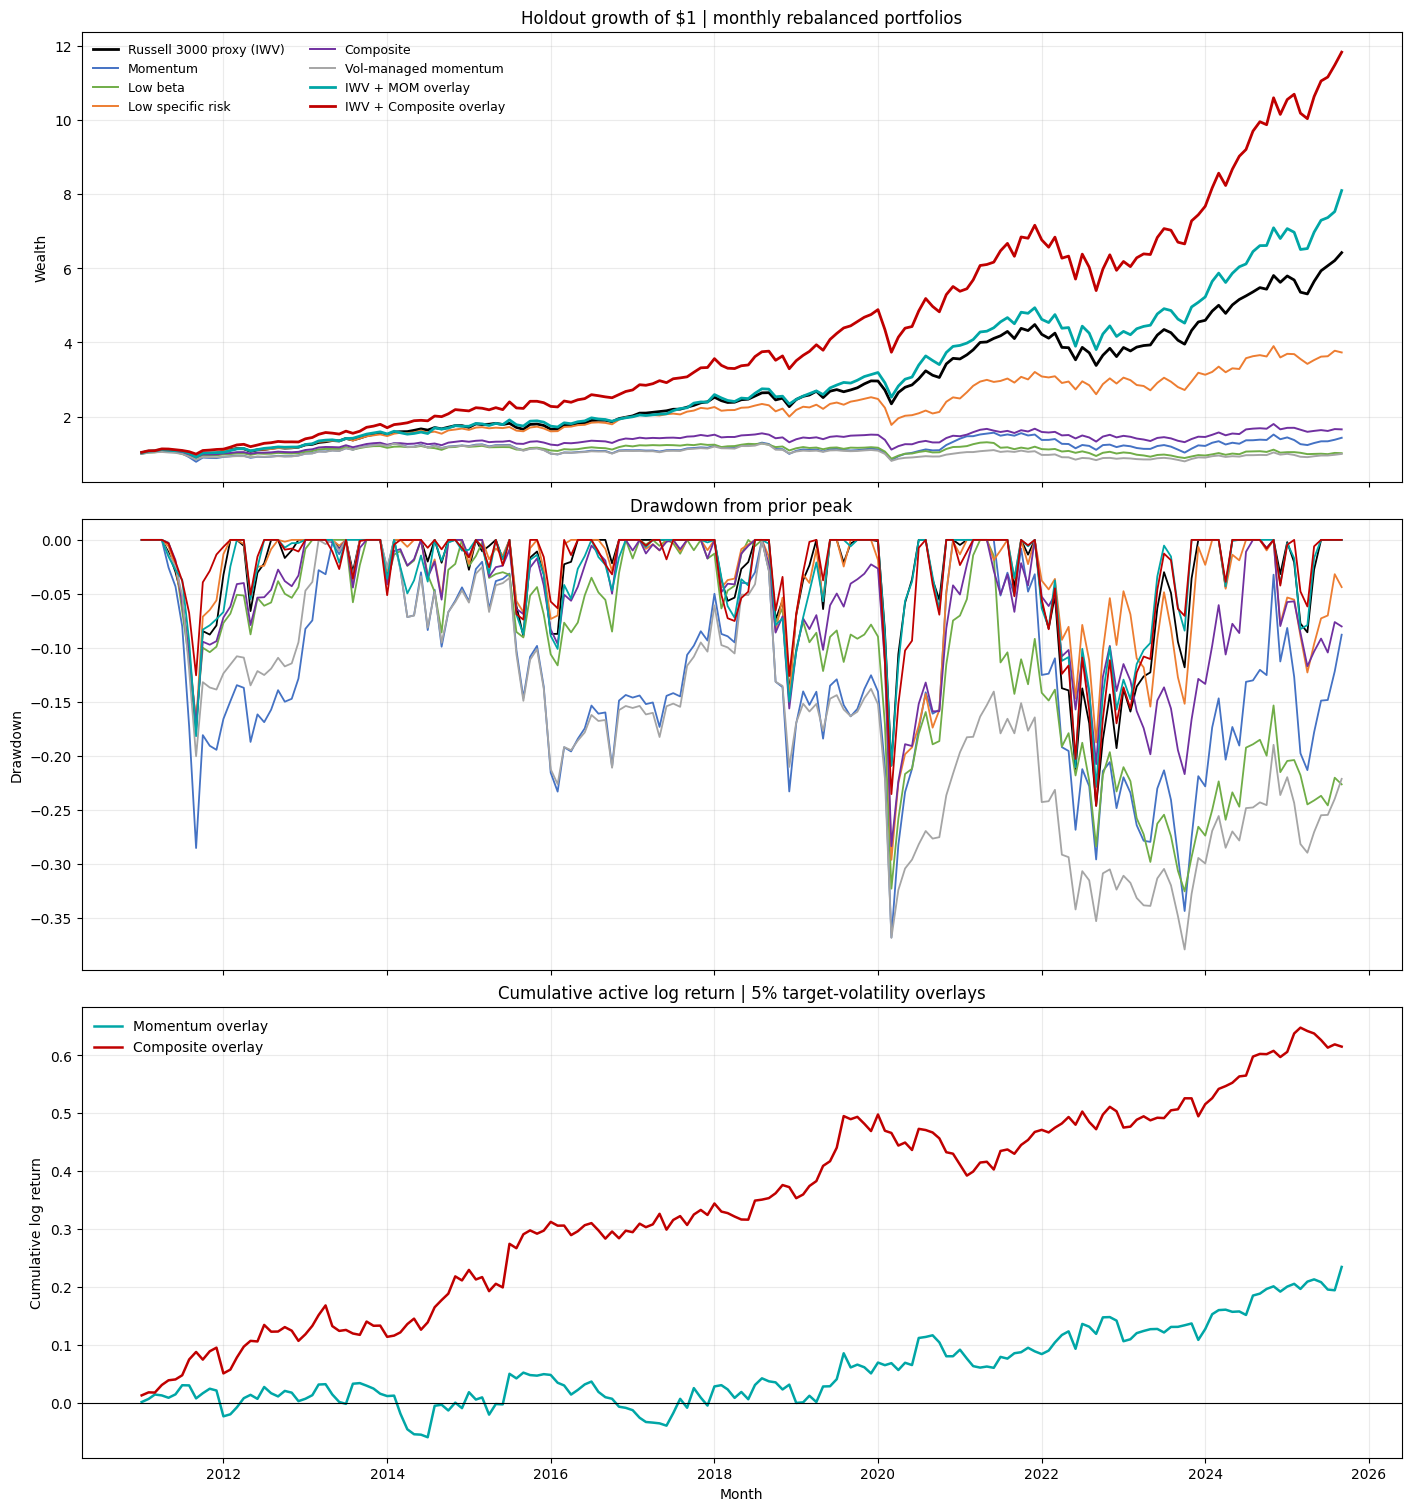

**Implementation notes.** Incomplete final month excluded; missing next-month outcomes within the sample are assigned −100% as a conservative delisting convention. The beta hedge uses supplied predicted beta, so forecast beta is zero by construction; see realized holdout beta. Sharpe uses rf=0. Transaction costs are assumption-based. IWV is an ETF proxy, not the Russell 3000 index series.

Benchmark: Yahoo Finance IWV adjusted close (ETF proxy); evaluation through 2025-09.
Panel: 19,129,651 daily rows; 9,162 IDs; monthly returns 2000-01 to 2025-09.
Median formation universe: 2,526 names/month after price and signal screens; monthly rebalance; 12–2 signal held next month.
Duplicate security-date rows removed: 0; returns below -100% excluded: 0; largest daily return retained: 880.0% (percent points).


In [ ]:
# multi-signal equity backtest | point-in-time monthly construction
import gc, json, urllib.parse, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

# clear memory-heavy objects from the superseded analysis; preserve loaded df.
for _v in ["d","m","h","mom","mom_d","mom_m","mom_r","r","managed","managed_fair","screened_mom","hold_mom","total","active_test","comparison","perf_table","stress_table","beta_audit","audit_hold"]:
    globals().pop(_v,None)
gc.collect()

# pre-specified choices: monthly rebalance; 12-2 momentum; 30% tails; holdout starts 2011.
PRICE_FLOOR, TOP_FRACTION = 5.0, 0.30
TRAIN_END, TEST_START = pd.Period("2010-12","M"), pd.Period("2011-01","M")
VOL_LOOKBACK, ACTIVE_VOL_TARGET, ACTIVE_GROSS_CAP = 12, 0.05, 3.0
required={"barrid","date","return","price","predicted_beta","specific_risk"}
assert required.issubset(df.columns), f"Missing: {required-set(df.columns)}"

# 1) daily-to-monthly stock panel. returns in the source are percent points.
raw=pd.DataFrame({
    "barrid":df["barrid"].astype("category"),
    "date":pd.to_datetime(df["date"],errors="coerce"),
    "ret_pct":pd.to_numeric(df["return"],errors="coerce").astype("float32"),
    "price":pd.to_numeric(df["price"],errors="coerce").astype("float32"),
    "beta":pd.to_numeric(df["predicted_beta"],errors="coerce").astype("float32"),
    "specific_risk":pd.to_numeric(df["specific_risk"],errors="coerce").astype("float32"),
})
raw["ret"]=raw["ret_pct"].astype("float64")/100.0
raw=raw.dropna(subset=["barrid","date","ret"])
invalid_returns=int((raw.ret < -1).sum())
raw=raw.loc[raw.ret>=-1].copy().sort_values(["barrid","date"],kind="mergesort")
duplicate_keys=int(raw.duplicated(["barrid","date"]).sum())
if duplicate_keys: raw=raw.drop_duplicates(["barrid","date"],keep="last")
# exclude the unfinished last month and all subsequent benchmark observations.
last_observation=raw.date.max()
last_period=last_observation.to_period("M")
LAST_COMPLETE_MONTH=last_period if last_observation.day==last_period.days_in_month else last_period-1
raw["gross"]=1.0+raw.ret
raw["month"]=raw.date.dt.to_period("M")
monthly=(raw.groupby(["barrid","month"],observed=True,sort=False)
    .agg(gross=("gross","prod"),price=("price","last"),beta=("beta","last"),
         specific_risk=("specific_risk","last"),daily_obs=("ret","size"))
    .reset_index())
monthly=monthly.loc[monthly.month<=LAST_COMPLETE_MONTH].copy()
monthly["stock_ret"]=monthly.gross-1.0
monthly["month_ord"]=monthly.month.astype("int64")
monthly=monthly.sort_values(["barrid","month"],kind="mergesort").reset_index(drop=True)
monthly["log_gross"]=np.log(monthly.gross.where(monthly.gross>0))
g=monthly.groupby("barrid",observed=True,sort=False)
log_12_2=g.log_gross.transform(lambda s:s.shift(1).rolling(11,min_periods=11).sum())
prev_ord=monthly.groupby("barrid",observed=True,sort=False).month_ord.shift(1)
old_ord=monthly.groupby("barrid",observed=True,sort=False).month_ord.shift(11)
complete_history=(prev_ord-old_ord).eq(10)&(monthly.month_ord-prev_ord).eq(1)
monthly["mom_12_2"]=np.expm1(log_12_2).where(complete_history)

# 2) iwv adjusted close, including distributions, as the russell 3000 etf proxy.
def get_iwv_returns():
    p1=int(pd.Timestamp("1999-01-01",tz="UTC").timestamp())
    p2=int(pd.Timestamp.now(tz="UTC").timestamp())
    query=urllib.parse.urlencode({"period1":p1,"period2":p2,"interval":"1d","events":"div,splits"})
    req=urllib.request.Request("https://query1.finance.yahoo.com/v8/finance/chart/IWV?"+query,headers={"User-Agent":"Mozilla/5.0"})
    with urllib.request.urlopen(req,timeout=30) as response: payload=json.loads(response.read().decode("utf-8"))
    result=payload["chart"]["result"][0]
    dates=pd.to_datetime(result["timestamp"],unit="s",utc=True).tz_convert(None)
    adj=result["indicators"].get("adjclose",[{}])[0].get("adjclose")
    if adj is None: raise ValueError("IWV adjusted closes missing from Yahoo response")
    px=pd.Series(adj,index=dates).dropna().sort_index()
    ret=px.resample("ME").last().pct_change().dropna()
    ret.index=ret.index.to_period("M"); ret.name="IWV"
    return ret
try:
    benchmark=get_iwv_returns()
    benchmark_source="Yahoo Finance IWV adjusted close (ETF proxy)"
except Exception as exc:
    prior=globals().get("bench",None)
    if prior is None: raise RuntimeError("IWV download failed. Upload monthly IWV data and rerun.") from exc
    benchmark=pd.Series(prior,dtype=float).dropna().copy()
    if not isinstance(benchmark.index,pd.PeriodIndex): benchmark.index=pd.to_datetime(benchmark.index).to_period("M")
    benchmark.name="IWV"; benchmark_source="Previously loaded IWV monthly series"
benchmark=benchmark.loc[benchmark.index<=LAST_COMPLETE_MONTH]

# 3) Month-end signals form next-month holdings; common data screen for all signals.
formation=monthly.loc[
    monthly.month.lt(LAST_COMPLETE_MONTH)&monthly.price.ge(PRICE_FLOOR)&monthly.mom_12_2.notna()
    &monthly.beta.notna()&monthly.specific_risk.gt(0),
    ["barrid","month","price","mom_12_2","beta","specific_risk"]
].copy()
formation["hold_month"]=formation.month+1
formation=formation.sort_values(["month","barrid"],kind="mergesort")
formation["mom_rank"]=formation.groupby("month",observed=True).mom_12_2.rank(pct=True,method="first")
formation["low_beta_rank"]=formation.groupby("month",observed=True).beta.rank(pct=True,ascending=False,method="first")
formation["low_specific_rank"]=formation.groupby("month",observed=True).specific_risk.rank(pct=True,ascending=False,method="first")
formation["combo_rank"]=formation[["mom_rank","low_beta_rank","low_specific_rank"]].mean(axis=1)
scores={"Momentum":"mom_rank","Low beta":"low_beta_rank","Low specific risk":"low_specific_rank","Composite":"combo_rank"}
blocks=[]
def add_book(sub,fm,hm,signal,book,weight):
    z=sub[["barrid","beta"]].copy(); z["formation_month"]=fm; z["holding_month"]=hm
    z["signal"]=signal; z["book"]=book; z["weight"]=weight; blocks.append(z)
for fm,group in formation.groupby("month",observed=True,sort=True):
    group=group.sort_values("barrid",kind="mergesort"); n=len(group)
    if not n: continue
    n_long=max(1,int(np.floor(n*TOP_FRACTION))); n_ls=min(n_long,n//2); hm=fm+1
    for signal,col in scores.items():
        high=group.sort_values([col,"barrid"],ascending=[False,True],kind="mergesort")
        add_book(high.head(n_long),fm,hm,signal,"Long-only",1.0/n_long)
        if n_ls:
            low=group.sort_values([col,"barrid"],ascending=[True,True],kind="mergesort")
            add_book(high.head(n_ls),fm,hm,signal,"Long-short",1.0/n_ls)
            add_book(low.head(n_ls),fm,hm,signal,"Long-short",-1.0/n_ls)
positions=pd.concat(blocks,ignore_index=True)
outcomes=monthly[["barrid","month","stock_ret"]].rename(columns={"month":"holding_month","stock_ret":"forward_ret"})
positions=positions.merge(outcomes,on=["barrid","holding_month"],how="left",validate="many_to_one")
positions["missing_forward"]=positions.forward_ret.isna()
# Conservative delisting convention: selected name absent next month loses 100%.
positions["forward_ret"]=positions.forward_ret.fillna(-1.0)
positions["pnl"]=positions.weight*positions.forward_ret
positions["beta_pnl"]=positions.weight*positions.beta
lo=positions[positions.book.eq("Long-only")].groupby(["holding_month","signal"],observed=True).pnl.sum().unstack("signal").sort_index()
ls=positions[positions.book.eq("Long-short")].groupby(["holding_month","signal"],observed=True).pnl.sum().unstack("signal").sort_index()
model_beta=positions[positions.book.eq("Long-short")].groupby(["holding_month","signal"],observed=True).beta_pnl.sum().unstack("signal").sort_index()

# 4) Dollar-neutral, forecast-beta-neutral active overlays; use lagged 12m risk.
# The long-short stock book is +1x/-1x; hedge its supplied predicted beta with IWV;
# offset the hedge's net weight with 0%-return cash. Maximum risky gross is 3x.
raw_active=ls.sub(model_beta.mul(benchmark,axis=0))
overlay=pd.DataFrame(index=raw_active.index); scale=pd.DataFrame(index=raw_active.index); gross=pd.DataFrame(index=raw_active.index)
for signal in ["Momentum","Composite"]:
    forecast=raw_active[signal].rolling(VOL_LOOKBACK,min_periods=VOL_LOOKBACK).std().shift(1)*np.sqrt(12)
    cap=ACTIVE_GROSS_CAP/(2.0+model_beta[signal].abs())
    lev=np.minimum(ACTIVE_VOL_TARGET/forecast,cap).where(forecast.notna(),0.0)
    lev=lev.replace([np.inf,-np.inf],np.nan).fillna(0.0).clip(lower=0.0)
    scale[signal]=lev; overlay[signal]=(raw_active[signal]*lev).fillna(0.0)
    gross[signal]=lev*(2.0+model_beta[signal].abs())
# 12% target-vol MOM long-only comparator, capped at 1x (de-risk only).
mom_vol=lo.Momentum.rolling(12,min_periods=12).std().shift(1)*np.sqrt(12)
lo["Vol-managed momentum"]=lo.Momentum*(0.12/mom_vol).clip(upper=1.0).fillna(1.0)
idx=benchmark.index.union(lo.index).union(overlay.index).sort_values()
market=benchmark.reindex(idx)
returns=pd.DataFrame(index=idx); returns["Russell 3000 proxy (IWV)"]=market
for s in ["Momentum","Low beta","Low specific risk","Composite","Vol-managed momentum"]: returns[s]=lo[s].reindex(idx)
returns["IWV + MOM overlay"]=market+overlay.Momentum.reindex(idx).fillna(0.0)
returns["IWV + Composite overlay"]=market+overlay.Composite.reindex(idx).fillna(0.0)

# 5) Geometric portfolio metrics; Sharpe uses rf=0 because no cash series is supplied.
def stats(port,bmk):
    z=pd.concat([port.rename("p"),bmk.rename("b")],axis=1).dropna(); p,b=z.p,z.b; n=len(z)
    if not n: return {"Months":0}
    w=(1+p).cumprod(); bw=(1+b).cumprod()
    cagr=w.iloc[-1]**(12/n)-1 if w.iloc[-1]>0 else -1.0
    bcagr=bw.iloc[-1]**(12/n)-1 if bw.iloc[-1]>0 else -1.0
    vol=p.std(ddof=1)*np.sqrt(12) if n>1 else np.nan
    sharpe=p.mean()/p.std(ddof=1)*np.sqrt(12) if n>1 and p.std(ddof=1)>0 else np.nan
    path=np.r_[1.0,w.to_numpy()]; dd=path/np.maximum.accumulate(path)-1
    active=p-b; te=active.std(ddof=1)*np.sqrt(12) if n>1 else np.nan
    ir=active.mean()/active.std(ddof=1)*np.sqrt(12) if n>1 and active.std(ddof=1)>0 else np.nan
    beta=np.cov(p,b,ddof=1)[0,1]/np.var(b,ddof=1) if n>2 and np.var(b,ddof=1)>0 else np.nan
    return {"Months":n,"CAGR":cagr,"Volatility":vol,"Sharpe (rf=0)":sharpe,"Max drawdown":dd.min(),"Beta":beta,"Active CAGR":cagr-bcagr,"Tracking error":te,"Information ratio":ir}
rows=[]
for sample,start,end in [("Development 2001–2010",pd.Period("2001-01","M"),TRAIN_END),("Holdout 2011 onward",TEST_START,LAST_COMPLETE_MONTH)]:
    for name in returns.columns:
        r=returns[name].loc[start:end]; s=stats(r,market.loc[start:end]); s.update({"Sample":sample,"Strategy":name}); rows.append(s)
performance=pd.DataFrame(rows).set_index(["Sample","Strategy"])
fmt={"CAGR":"{:.1%}","Volatility":"{:.1%}","Sharpe (rf=0)":"{:.2f}","Max drawdown":"{:.1%}","Beta":"{:.2f}","Active CAGR":"{:+.1%}","Tracking error":"{:.1%}","Information ratio":"{:.2f}"}
display(Markdown("## Holdout performance | January 2011 onward")); display(performance.loc["Holdout 2011 onward"].style.format(fmt))
display(Markdown("### Development sample | fixed rules, 2001–2010")); display(performance.loc["Development 2001–2010"].style.format(fmt))

# Long-short spreads are arithmetic factor returns on 1x long + 1x short (gross 2x), not compounded wealth.
ls_rows=[]
for s in ls.columns:
    z=pd.concat([ls[s].loc[ls.index>=TEST_START].rename("p"),benchmark.rename("b")],axis=1).dropna()
    if len(z)>1:
        b=np.cov(z.p,z.b,ddof=1)[0,1]/np.var(z.b,ddof=1)
        ls_rows.append({"Signal spread (gross 2x)":s,"Annualized mean":z.p.mean()*12,"Annualized volatility":z.p.std(ddof=1)*np.sqrt(12),"Sharpe (rf=0)":z.p.mean()/z.p.std(ddof=1)*np.sqrt(12),"Realized beta":b})
ls_table=pd.DataFrame(ls_rows).set_index("Signal spread (gross 2x)")
display(Markdown("### Standalone signal-spread diagnostics | holdout")); display(ls_table.style.format({"Annualized mean":"{:+.1%}","Annualized volatility":"{:.1%}","Sharpe (rf=0)":"{:.2f}","Realized beta":"{:.2f}"}))

# Mean monthly cross-sectional rank correlations assess signal overlap.
corr_rows=[]
for a,b in [("mom_rank","low_beta_rank"),("mom_rank","low_specific_rank"),("low_beta_rank","low_specific_rank")]:
    by_month=formation.groupby("month",observed=True,sort=False)
    vals=[q[a].corr(q[b]) for _,q in by_month]
    corr_rows.append({"Signal pair":f"{a} vs {b}","Mean monthly rank correlation":np.nanmean(vals)})
display(Markdown("### Signal diversification check")); display(pd.DataFrame(corr_rows).set_index("Signal pair").style.format("{:.2f}"))

# Turnover/cost sensitivity: target-weight changes; no mark-to-market drift or market impact.
def target_path(signal,bps):
    z=positions[(positions.book=="Long-only")&(positions.signal==signal)]; prev={}; out=[]
    for month,gp in z.groupby("holding_month",observed=True,sort=True):
        target=dict(zip(gp.barrid.astype(str),gp.weight.astype(float))); keys=set(target)|set(prev)
        traded=sum(abs(target.get(k,0)-prev.get(k,0)) for k in keys) if prev else 1.0
        out.append({"month":month,"net":float(gp.pnl.sum())-traded*bps/10000,"turnover":traded}); prev=target
    return pd.DataFrame(out).set_index("month")
cost_rows=[]
for s in ["Momentum","Composite"]:
    for bps in [0,10,25]:
        p=target_path(s,bps); p=p.loc[(p.index>=TEST_START)&(p.index<=LAST_COMPLETE_MONTH)]
        q=stats(p.net,benchmark.reindex(p.index))
        cost_rows.append({"Strategy":s,"Cost (bps/traded dollar)":bps,"Holdout CAGR":q.get("CAGR",np.nan),"Annual traded notional/NAV":p.turnover.mean()*12})
cost_table=pd.DataFrame(cost_rows).set_index(["Strategy","Cost (bps/traded dollar)"])
display(Markdown("### Cost sensitivity | assumed bps, not measured spreads; turnover proxy ignores intra-month drift"))
display(cost_table.style.format({"Holdout CAGR":"{:+.1%}","Annual traded notional/NAV":"{:.1f}x"}))

# 6) Exposure, calendar-year, and fixed stress-window reports.
checks=[]
for s in ["Momentum","Composite"]:
    checks.append({"Overlay":s,"Target net weight":0.0,"Forecast beta after hedge":0.0,"Average risky gross":gross[s].mean(),"Maximum risky gross":gross[s].max(),"Vol target":ACTIVE_VOL_TARGET,"Rebalance":"Monthly"})
display(Markdown("### Overlay design and leverage")); display(pd.DataFrame(checks).set_index("Overlay").style.format({"Target net weight":"{:.2f}","Forecast beta after hedge":"{:.2f}","Average risky gross":"{:.2f}x","Maximum risky gross":"{:.2f}x","Vol target":"{:.1%}"}))
active_rows=[]
for s in ["Momentum","Composite"]:
    z=pd.concat([overlay[s].loc[overlay.index>=TEST_START].rename("a"),benchmark.rename("b")],axis=1).dropna()
    if len(z)>1:
        b=np.cov(z.a,z.b,ddof=1)[0,1]/np.var(z.b,ddof=1)
        active_rows.append({"Overlay":s,"Holdout active volatility":z.a.std(ddof=1)*np.sqrt(12),"Holdout active mean":z.a.mean()*12,"Realized beta to IWV":b,"Average scale":scale[s].reindex(z.index).mean(),"Average risky gross":gross[s].reindex(z.index).mean()})
display(Markdown("### Holdout overlay diagnostics | realized risk can differ from target")); display(pd.DataFrame(active_rows).set_index("Overlay").style.format({"Holdout active volatility":"{:.1%}","Holdout active mean":"{:+.1%}","Realized beta to IWV":"{:.2f}","Average scale":"{:.2f}x","Average risky gross":"{:.2f}x"}))

annual_names=["Russell 3000 proxy (IWV)","IWV + MOM overlay","IWV + Composite overlay"]
annual_data=returns[annual_names].loc[returns.index>=TEST_START].dropna(); annual=[]
for year,gy in annual_data.groupby(annual_data.index.year):
    for s in annual_names:
        x=gy[s].dropna()
        if len(x): annual.append({"Year":year,"Months":len(x),"Strategy":s,"Calendar return":(1+x).prod()-1,"Annualized monthly vol":x.std(ddof=1)*np.sqrt(12) if len(x)>1 else np.nan})
annual_table=pd.DataFrame(annual).set_index(["Year","Strategy"])
display(Markdown("### Calendar-year comparison | 2025 is partial through the last complete data month")); display(annual_table.style.format({"Calendar return":"{:+.1%}","Annualized monthly vol":"{:.1%}"}))
stress={"GFC (Oct 2007–Mar 2009)":("2007-10","2009-03"),"COVID selloff (Feb–Apr 2020)":("2020-02","2020-04"),"2022 calendar year":("2022-01","2022-12")}
stress_rows=[]
for window,(a,b) in stress.items():
    for s in ["Russell 3000 proxy (IWV)","Momentum","Low beta","Low specific risk","Composite","Vol-managed momentum","IWV + MOM overlay","IWV + Composite overlay"]:
        x=returns[s].loc[pd.Period(a,"M"):pd.Period(b,"M")].dropna()
        if len(x):
            w=(1+x).cumprod(); path=np.r_[1.0,w.to_numpy()]; dd=path/np.maximum.accumulate(path)-1
            stress_rows.append({"Window":window,"Strategy":s,"Months":len(x),"Window return":w.iloc[-1]-1,"Max drawdown":dd.min()})
stress_table=pd.DataFrame(stress_rows).set_index(["Window","Strategy"])
display(Markdown("### Pre-specified stress windows")); display(stress_table.style.format({"Window return":"{:+.1%}","Max drawdown":"{:.1%}"}))

# 7) Holdout visuals: absolute wealth, drawdown, and active log return.
plot_names=["Russell 3000 proxy (IWV)","Momentum","Low beta","Low specific risk","Composite","Vol-managed momentum","IWV + MOM overlay","IWV + Composite overlay"]
pr=returns[plot_names].loc[(returns.index>=TEST_START)&(returns.index<=LAST_COMPLETE_MONTH)].dropna(how="all")
wealth=(1+pr).cumprod()
fig,ax=plt.subplots(3,1,figsize=(14,15),sharex=True,constrained_layout=True)
colors={"Russell 3000 proxy (IWV)":"black","Momentum":"#4472C4","Low beta":"#70AD47","Low specific risk":"#ED7D31","Composite":"#7030A0","Vol-managed momentum":"#A5A5A5","IWV + MOM overlay":"#00A6A6","IWV + Composite overlay":"#C00000"}
for s in plot_names: ax[0].plot(wealth.index.to_timestamp(),wealth[s],label=s,color=colors[s],lw=2 if "IWV" in s else 1.4)
ax[0].set_title("Holdout growth of $1 | monthly rebalanced portfolios"); ax[0].set_ylabel("Wealth"); ax[0].legend(ncol=2,frameon=False,fontsize=9); ax[0].grid(alpha=.25)
for s in plot_names:
    w=wealth[s].dropna()
    if len(w): ax[1].plot(w.index.to_timestamp(),w/w.cummax()-1,label=s,color=colors[s],lw=1.3)
ax[1].set_title("Drawdown from prior peak"); ax[1].set_ylabel("Drawdown"); ax[1].grid(alpha=.25)
for s,label,color in [("Momentum","Momentum overlay",colors["IWV + MOM overlay"]),("Composite","Composite overlay",colors["IWV + Composite overlay"])]:
    x=overlay[s].loc[(overlay.index>=TEST_START)&(overlay.index<=LAST_COMPLETE_MONTH)].clip(lower=-.999999)
    ax[2].plot(x.index.to_timestamp(),np.log1p(x).cumsum(),label=label,color=color,lw=1.8)
ax[2].axhline(0,color="black",lw=.8); ax[2].set_title("Cumulative active log return | 5% target-volatility overlays"); ax[2].set_ylabel("Cumulative log return"); ax[2].set_xlabel("Month"); ax[2].legend(frameon=False); ax[2].grid(alpha=.25)
plt.show()

missing_share=positions.loc[positions.holding_month<=LAST_COMPLETE_MONTH].groupby(["book","signal"],observed=True).missing_forward.mean().rename("Missing next-month outcome share")
display(Markdown("**Implementation notes.** Incomplete final month excluded; missing next-month outcomes within the sample are assigned −100% as a conservative delisting convention. The beta hedge uses supplied predicted beta, so forecast beta is zero by construction; see realized holdout beta. Sharpe uses rf=0. Transaction costs are assumption-based. IWV is an ETF proxy, not the Russell 3000 index series.")); display(missing_share.to_frame().style.format("{:.2%}"))
print(f"Benchmark: {benchmark_source}; evaluation through {LAST_COMPLETE_MONTH}.")
print(f"Panel: {len(raw):,} daily rows; {monthly.barrid.nunique():,} IDs; monthly returns {monthly.month.min()} to {monthly.month.max()}.")
print(f"Median formation universe: {formation.groupby('month',observed=True).size().median():,.0f} names/month after price and signal screens; monthly rebalance; 12–2 signal held next month.")
print(f"Duplicate security-date rows removed: {duplicate_keys:,}; returns below -100% excluded: {invalid_returns:,}; largest daily return retained: {raw.ret_pct.max():.1f}% (percent points).")

In [ ]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd

display(Markdown("""
## Missing-return assumption sensitivity

The **−100% treatment remains the primary baseline**. These cases rescore holdings already selected at formation; missingness does not change selection. The exclude-and-reweight case is a **diagnostic only** because dropping missing outcomes can create survivorship bias. It reweights within each book or long/short side. If an entire long-short side has no observed outcomes, that month's diagnostic return is unavailable.

The overlay uses the existing scale so this comparison isolates the missing-return assumption. Metrics are gross, matching the main performance table.
"""))

# Restrict the analysis to the existing holdout period.
_sens_months = returns.index[
    (returns.index >= TEST_START) & (returns.index <= LAST_COMPLETE_MONTH)
].sort_values()
assert _sens_months.is_unique and _sens_months.is_monotonic_increasing

_sens_iwv = returns["Russell 3000 proxy (IWV)"].reindex(_sens_months).astype(float)
_sens_pos = positions.loc[
    positions["signal"].eq("Composite")
    & positions["holding_month"].isin(_sens_months)
].copy()
_sens_pos["missing_forward"] = (
    _sens_pos["missing_forward"].fillna(False).astype(bool)
)
_sens_pos["side"] = np.where(_sens_pos["weight"].lt(0), "Short", "Long")

def _sensitivity_books(case):
    """Rescore the fixed Composite holdings under one missing-return rule."""
    q = _sens_pos.copy()
    q["scenario_return"] = q["forward_ret"].astype(float)

    if case == "baseline":
        q.loc[q["missing_forward"], "scenario_return"] = -1.0
        q["scenario_weight"] = q["weight"].astype(float)
    elif case == "zero":
        q.loc[q["missing_forward"], "scenario_return"] = 0.0
        q["scenario_weight"] = q["weight"].astype(float)
    elif case == "exclude":
        q = q.loc[~q["missing_forward"]].copy()
        side_keys = ["holding_month", "book", "side"]
        side_gross = q.groupby(side_keys, observed=True)["weight"].transform(
            lambda w: w.abs().sum()
        )
        q["scenario_weight"] = q["weight"].astype(float) / side_gross
    else:
        raise ValueError(f"Unknown sensitivity case: {case}")

    # Verify the existing +1 long / -1 short weight convention.
    weight_sums = q.groupby(
        ["holding_month", "book", "side"], observed=True
    )["scenario_weight"].sum()
    targets = np.where(
        weight_sums.index.get_level_values("side") == "Short", -1.0, 1.0
    )
    assert np.allclose(weight_sums.to_numpy(), targets, atol=1e-10), (
        f"{case}: portfolio-side weights do not preserve the +1/-1 convention"
    )

    q["scenario_pnl"] = q["scenario_weight"] * q["scenario_return"]
    q["scenario_beta_pnl"] = q["scenario_weight"] * q["beta"].astype(float)

    long_only = (
        q.loc[q["book"].eq("Long-only")]
        .groupby("holding_month", observed=True)["scenario_pnl"]
        .sum()
        .reindex(_sens_months)
    )

    ls_q = q.loc[q["book"].eq("Long-short")]
    long_short = (
        ls_q.groupby("holding_month", observed=True)["scenario_pnl"]
        .sum()
        .reindex(_sens_months)
    )
    beta_book = (
        ls_q.groupby("holding_month", observed=True)["scenario_beta_pnl"]
        .sum()
        .reindex(_sens_months)
    )

    if case == "exclude":
        kept_sides = (
            ls_q.groupby("holding_month", observed=True)["side"]
            .nunique()
            .reindex(_sens_months, fill_value=0)
        )
        expected_sides = (
            _sens_pos.loc[_sens_pos["book"].eq("Long-short")]
            .groupby("holding_month", observed=True)["side"]
            .nunique()
            .reindex(_sens_months, fill_value=0)
        )
        valid_month = kept_sides.eq(expected_sides)
        long_short = long_short.where(valid_month)
        beta_book = beta_book.where(valid_month)

    return long_only.astype(float), long_short.astype(float), beta_book.astype(float)

def _assert_series_close(actual, expected, label):
    actual = pd.Series(actual).reindex(_sens_months).astype(float)
    expected = pd.Series(expected).reindex(_sens_months).astype(float)
    assert actual.index.equals(expected.index), f"{label}: month indexes differ"
    assert np.allclose(
        actual.to_numpy(),
        expected.to_numpy(),
        rtol=1e-10,
        atol=1e-10,
        equal_nan=True,
    ), f"{label}: baseline does not reproduce the existing series"

# Confirm that the baseline reproduces the notebook's current calculations.
_base_lo, _base_ls, _base_beta = _sensitivity_books("baseline")
_assert_series_close(_base_lo, returns["Composite"], "Composite long-only")
_assert_series_close(_base_ls, ls["Composite"], "Composite long-short")
_assert_series_close(_base_beta, model_beta["Composite"], "Composite beta book")

def _sensitivity_overlay(long_short_returns, beta_returns):
    long_short_returns = long_short_returns.reindex(_sens_months).astype(float)
    beta_returns = beta_returns.reindex(_sens_months).astype(float)
    existing_scale = scale["Composite"].reindex(_sens_months).astype(float).fillna(0.0)
    active_return = long_short_returns - beta_returns * _sens_iwv
    return _sens_iwv + active_return * existing_scale

_base_overlay = _sensitivity_overlay(_base_ls, _base_beta)
_assert_series_close(
    _base_overlay,
    returns["IWV + Composite overlay"],
    "Composite overlay",
)

_zero_lo, _zero_ls, _zero_beta = _sensitivity_books("zero")
_zero_overlay = _sensitivity_overlay(_zero_ls, _zero_beta)

_excl_lo, _excl_ls, _excl_beta = _sensitivity_books("exclude")
_excl_overlay = _sensitivity_overlay(_excl_ls, _excl_beta)

_sensitivity_series = {
    "Baseline: missing = −100%": {
        "IWV benchmark": _sens_iwv,
        "Composite | long-only": _base_lo,
        "IWV + Composite overlay": _base_overlay,
    },
    "Zero-return assumption": {
        "IWV benchmark": _sens_iwv,
        "Composite | long-only": _zero_lo,
        "IWV + Composite overlay": _zero_overlay,
    },
    "Exclude-and-reweight diagnostic": {
        "IWV benchmark": _sens_iwv,
        "Composite | long-only": _excl_lo,
        "IWV + Composite overlay": _excl_overlay,
    },
}

_metric_rows = []
for case_name, portfolios in _sensitivity_series.items():
    for portfolio_name, portfolio_returns in portfolios.items():
        row = stats(portfolio_returns, _sens_iwv)
        row.update({"Case": case_name, "Portfolio": portfolio_name})
        _metric_rows.append(row)

_sens_metrics = pd.DataFrame(_metric_rows).set_index(["Case", "Portfolio"])
_baseline_metrics = _sens_metrics.xs(
    "Baseline: missing = −100%", level="Case"
)

for metric in _baseline_metrics.columns:
    _sens_metrics[f"Δ {metric} vs baseline"] = [
        (
            row[metric] - _baseline_metrics.loc[portfolio, metric]
            if pd.notna(row[metric])
            and pd.notna(_baseline_metrics.loc[portfolio, metric])
            else np.nan
        )
        for (case, portfolio), row in _sens_metrics.iterrows()
    ]

_metric_format = {
    "Months": "{:.0f}",
    "Δ Months vs baseline": "{:+.0f}",
    "CAGR": "{:.2%}",
    "Volatility": "{:.2%}",
    "Sharpe (rf=0)": "{:.2f}",
    "Max drawdown": "{:.2%}",
    "Beta": "{:.2f}",
    "Active CAGR": "{:+.2%}",
    "Tracking error": "{:.2%}",
    "Information ratio": "{:.2f}",
    "Δ CAGR vs baseline": "{:+.2%}",
    "Δ Volatility vs baseline": "{:+.2%}",
    "Δ Sharpe (rf=0) vs baseline": "{:+.2f}",
    "Δ Max drawdown vs baseline": "{:+.2%}",
    "Δ Beta vs baseline": "{:+.2f}",
    "Δ Active CAGR vs baseline": "{:+.2%}",
    "Δ Tracking error vs baseline": "{:+.2%}",
    "Δ Information ratio vs baseline": "{:+.2f}",
}
display(Markdown("### Composite and IWV holdout performance by case"))
display(_sens_metrics.style.format(_metric_format))

# Missing-outcome counts and absolute-weight shares, by month and overall.
_cov = _sens_pos.copy()
_cov["abs_weight"] = _cov["weight"].astype(float).abs()
_cov["missing_abs_weight"] = _cov["abs_weight"].where(
    _cov["missing_forward"], 0.0
)

_cov_month = _cov.groupby(
    ["holding_month", "book", "side"], observed=True, sort=True
).agg(
    selected_holdings=("barrid", "size"),
    missing_holdings=("missing_forward", "sum"),
    missing_abs_weight=("missing_abs_weight", "sum"),
    total_abs_weight=("abs_weight", "sum"),
)
_cov_month["missing_weight_share"] = (
    _cov_month["missing_abs_weight"] / _cov_month["total_abs_weight"]
)
_cov_month.index.names = ["Holding month", "Book", "Side"]

display(Markdown(
    "### Composite missing returns by month\n\n"
    "Weight share uses absolute weights; long and short sides are reported separately."
))
display(_cov_month.style.format({
    "selected_holdings": "{:.0f}",
    "missing_holdings": "{:.0f}",
    "missing_abs_weight": "{:.3f}",
    "total_abs_weight": "{:.3f}",
    "missing_weight_share": "{:.2%}",
}))

_cov_overall = _cov.groupby(["book", "side"], observed=True, sort=True).agg(
    holdout_months=("holding_month", "nunique"),
    selected_position_months=("barrid", "size"),
    missing_position_months=("missing_forward", "sum"),
    missing_abs_weight=("missing_abs_weight", "sum"),
    total_abs_weight=("abs_weight", "sum"),
)
_cov_overall["missing_outcome_rate"] = (
    _cov_overall["missing_position_months"]
    / _cov_overall["selected_position_months"]
)
_cov_overall["missing_weight_share"] = (
    _cov_overall["missing_abs_weight"] / _cov_overall["total_abs_weight"]
)

display(Markdown("### Composite missing returns overall"))
display(_cov_overall.style.format({
    "holdout_months": "{:.0f}",
    "selected_position_months": "{:.0f}",
    "missing_position_months": "{:.0f}",
    "missing_abs_weight": "{:.3f}",
    "total_abs_weight": "{:.3f}",
    "missing_outcome_rate": "{:.2%}",
    "missing_weight_share": "{:.2%}",
}))

print(
    "Checks passed: baseline matches existing Composite and overlay results; "
    "weights preserve the +1/-1 long-short convention; "
    "scenario series use the same holdout months."
)


## Missing-return assumption sensitivity

The **−100% treatment remains the primary baseline**. These cases rescore holdings already selected at formation; missingness does not change selection. The exclude-and-reweight case is a **diagnostic only** because dropping missing outcomes can create survivorship bias. It reweights within each book or long/short side. If an entire long-short side has no observed outcomes, that month's diagnostic return is unavailable.

The overlay uses the existing scale so this comparison isolates the missing-return assumption. Metrics are gross, matching the main performance table.


### Composite and IWV holdout performance by case

### Composite missing returns by month

Weight share uses absolute weights; long and short sides are reported separately.

### Composite missing returns overall

Checks passed: baseline matches existing Composite and overlay results; weights preserve the +1/-1 long-short convention; scenario series use the same holdout months.


## Results summary

We tested 12–2 momentum, low predicted beta, low specific risk, and an equal-weight composite of those three ranks. We formed portfolios monthly, fixed the rules on 2001–2010 data, and evaluated them on the 177-month holdout from January 2011 through September 2025. IWV is the ETF proxy for the Russell 3000.

Before costs, the composite overlay on IWV returned 18.24% annualized, versus 13.44% for IWV. Its realized beta was 0.99 and its maximum drawdown was −24.6%. The 4.8 percentage-point difference is the gross annualized return gap; it is not a forecast.

The CRSP-based cost section below uses actual monthly portfolio turnover after prior holdings drift, stock-level quoted half-spreads when available, and monthly median estimates otherwise. Composite-overlay CAGR is 18.04% after estimated stock and ETF spreads with no borrow charge, 17.57% with a 1% annual borrow assumption, and 15.69% with a 5% assumption. The comparable IWV holdout return is 13.44%; the benchmark is buy-and-hold in this period and has no monthly turnover cost. The 1% and 5% borrow rates are sensitivity assumptions because borrow fees were not supplied.

Direct dated quotes cover 9.5% of the composite overlay’s traded stock notional; 88.3% of traded stock notional maps to a CRSP identifier. Most spread estimates therefore use a monthly median or the file-wide fallback. No identifiable IWV quote series or stock-borrow data was supplied. Costs exclude commissions, market impact, recalls and borrow availability, financing, cash interest, taxes, and ETF expense ratios. These net figures are estimates with meaningful data gaps.

The original 0/10/25 bps turnover-proxy table above is preliminary; use the CRSP-based cost tables below for the updated cost comparison. The composite overlay did not prevent losses in every stress period, and the historical results do not prove future outperformance.

## CRSP comparison and observed-spread cost extension

The signal ranks, holdings, and judge/BotQ returns above are unchanged. The CRSP return series below uses those same holdings and only securities with a unique same-month CUSIP8-to-PERMNO match; matched holdings are reweighted within each long or short side, and the coverage columns show how much of the original portfolio was represented. Transaction costs use the observed CRSP daily relative half-spread at the last quote strictly before formation (up to 7 calendar days old), with the month median CRSP spread imputed when a holding has no usable direct quote. Costs include entries, exits, and rebalancing after return drift.

### Long-only signal results | holdout period: 2011-01

,Signal,Months,Judge gross CAGR,CRSP spread-cost net CAGR,CRSP matched-return CAGR,Judge gross Sharpe,Net Sharpe,CRSP return weight coverage,PERMNO mapped weight,Direct quote weight
0,Composite,177,3.5%,3.3%,12.0%,0.33,0.31,92.0%,88.4%,7.5%
1,Low beta,177,0.1%,-0.1%,11.8%,0.07,0.06,91.8%,88.4%,7.4%
2,Low specific risk,177,9.3%,9.3%,12.2%,0.67,0.67,92.1%,88.0%,7.5%
3,Momentum,177,2.4%,2.2%,13.7%,0.23,0.21,90.3%,87.2%,7.5%


### Long-short signal results | holdout period: 2011-01

,Signal,Months,Judge gross CAGR,CRSP spread-cost net CAGR,CRSP matched-return CAGR,Judge gross Sharpe,Net Sharpe,CRSP return weight coverage,PERMNO mapped weight,Direct quote weight
0,Composite,177,-0.8%,-1.2%,-1.5%,0.04,0.02,89.7%,86.3%,7.5%
1,Low beta,177,-7.1%,-7.4%,-2.7%,-0.33,-0.35,89.9%,86.5%,7.3%
2,Low specific risk,177,9.6%,9.4%,-1.9%,0.70,0.69,89.6%,86.2%,7.6%
3,Momentum,177,-0.0%,-0.6%,2.2%,0.06,0.01,89.4%,86.1%,7.6%


### Identifier and quote coverage

,Signal,Book,PERMNO mapped weight,Ambiguous CUSIP weight,Direct quote weight,CRSP monthly return weight,Median half-spread used
0,Momentum,Long-only,87.2%,0.0%,7.5%,86.4%,0.053%
1,Momentum,Long-short,86.1%,0.0%,7.6%,85.7%,0.053%
2,Low beta,Long-only,88.4%,0.0%,7.4%,87.6%,0.052%
3,Low beta,Long-short,86.5%,0.0%,7.3%,86.0%,0.053%
4,Low specific risk,Long-only,88.0%,0.0%,7.5%,87.8%,0.052%
5,Low specific risk,Long-short,86.2%,0.0%,7.6%,85.8%,0.053%
6,Composite,Long-only,88.4%,0.0%,7.5%,87.7%,0.052%
7,Composite,Long-short,86.3%,0.0%,7.5%,85.9%,0.053%


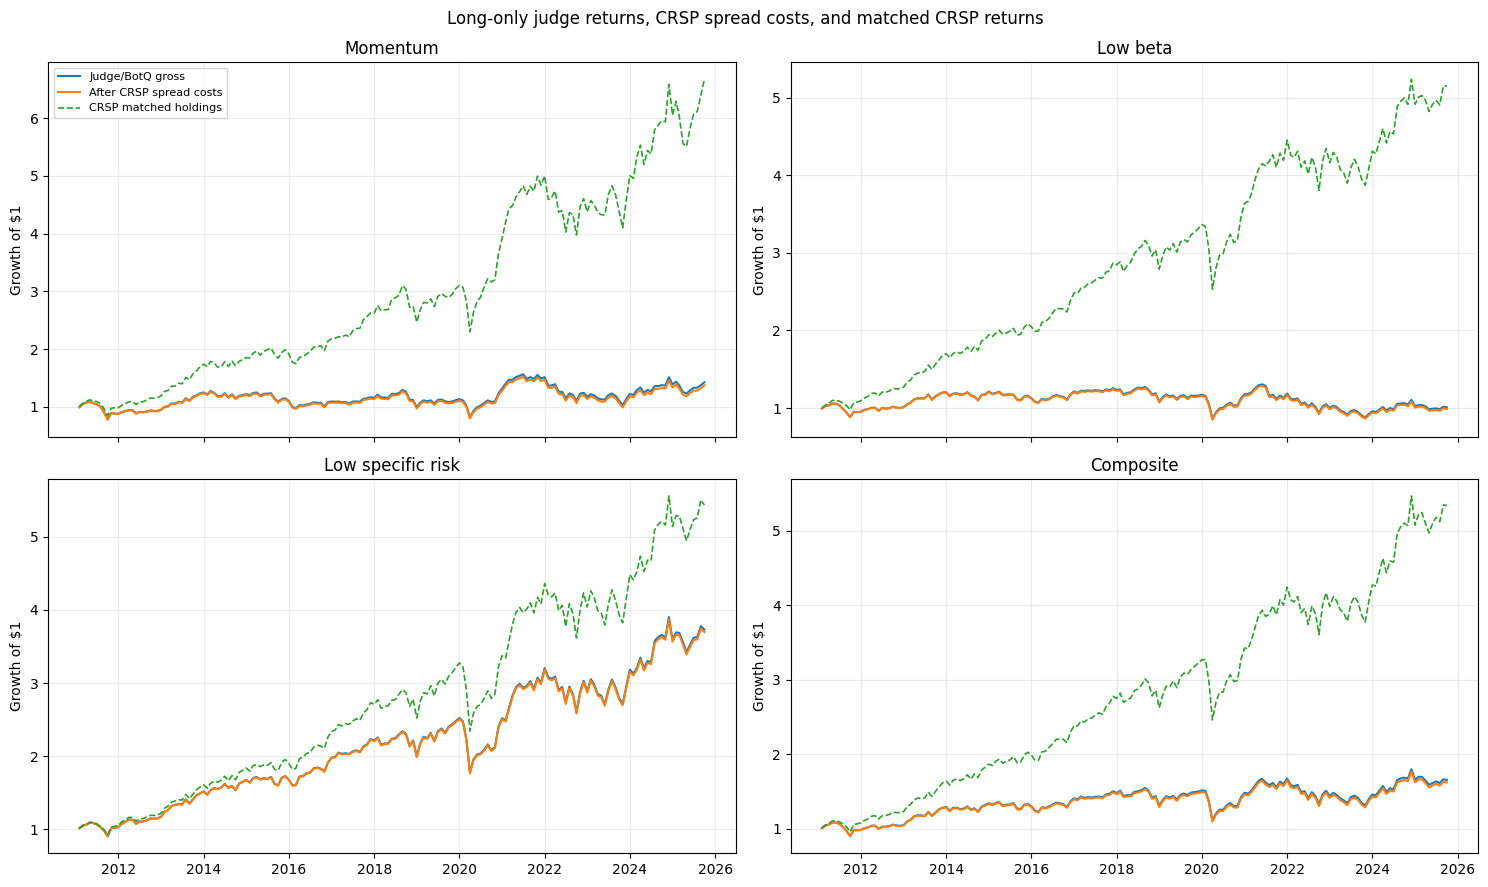

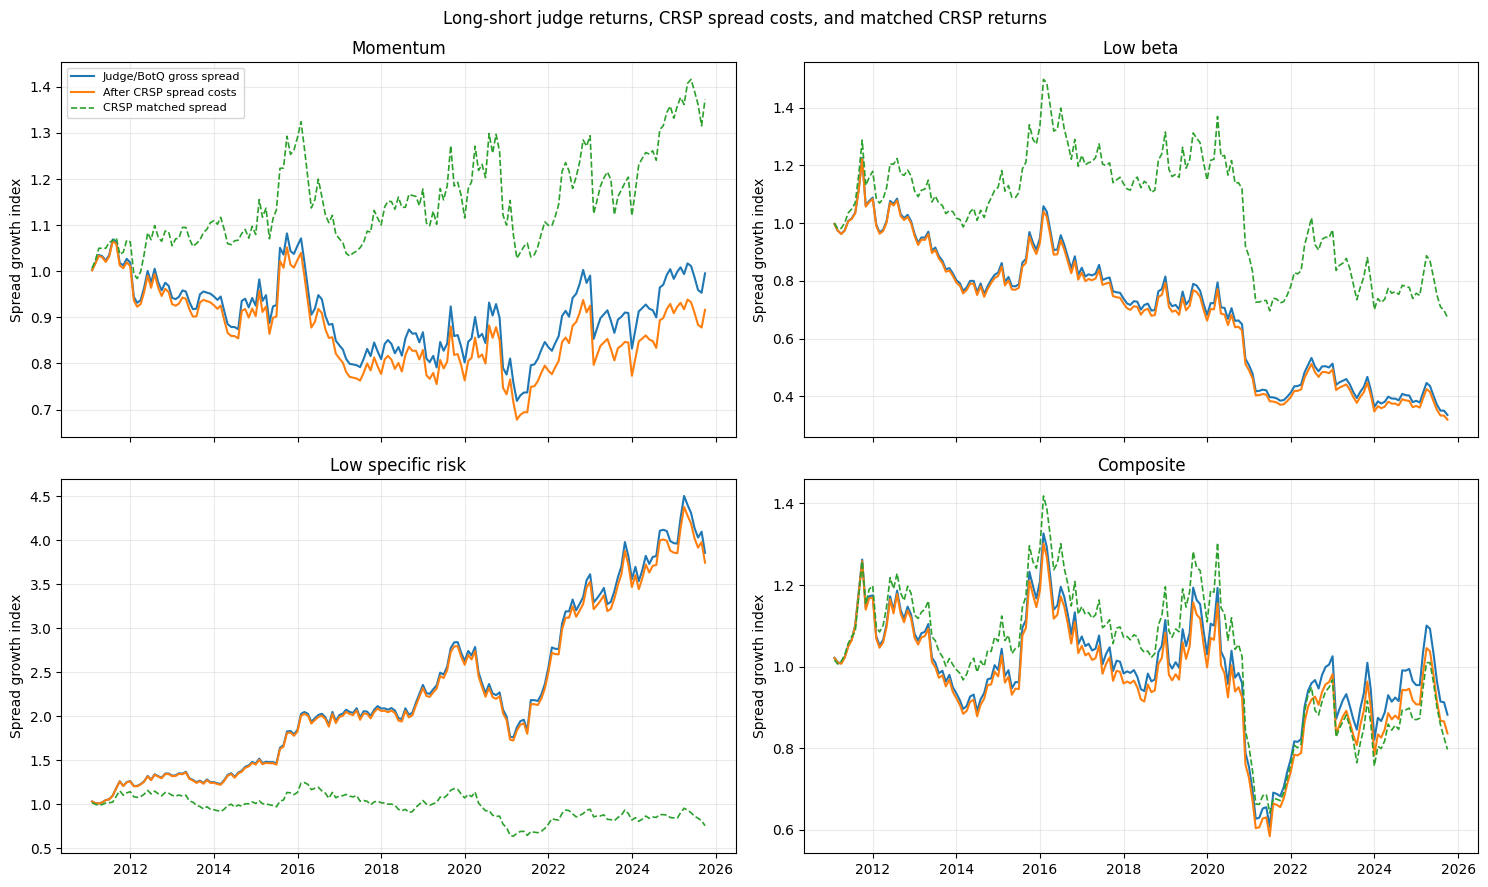

**Interpretation and limits.** The CRSP monthly-return figures are a matched-holdings cross-check, not a replacement for the full judge universe. CUSIP is matched within the formation month, and ambiguous CUSIP-month links are excluded. Daily quote costs use quoted bid/ask spreads; the notebook has no execution prices, commissions, market impact, or stock-borrow fees. The monthly-median spread fill is an estimate for holdings without a usable dated quote, so use the coverage table when interpreting net results.

CRSP monthly source: apr9ityqqqaopdzs.csv | rows: 2,371,997
CRSP daily quote source: x55hyh5gg7evz7fi.csv.gz | valid quote rows: 2,008,379
Monthly median spread imputation fallback (full file): 0.060%


In [ ]:
# CRSP matched-return cross-check and daily bid/ask trading-cost extension
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Preserve the judge/BotQ backtest outputs above. This section adds separate CRSP series.
if 'positions' not in globals() or 'df' not in globals():
    raise RuntimeError('Run the original BotQ signal cell before this CRSP section.')

# Locate the uploaded CRSP files by their field names, not their generated filenames.
_crsp_paths = glob.glob('/content/*.csv*')
_crsp_headers = {}
for _path in _crsp_paths:
    try:
        _crsp_headers[_path] = pd.read_csv(_path, nrows=0).columns.tolist()
    except Exception:
        pass

def _lower_col_map(cols):
    return {str(c).strip().lower(): c for c in cols}

_monthly_path = None
_daily_path = None
for _path, _cols in _crsp_headers.items():
    _cm = _lower_col_map(_cols)
    if {'permno','hdrcusip','mthcaldt','mthret'}.issubset(_cm):
        _monthly_path = _path
    if {'permno','dlycaldt','dlybid','dlyask'}.issubset(_cm):
        _daily_path = _path
if _monthly_path is None or _daily_path is None:
    raise FileNotFoundError('Could not identify both uploaded CRSP files. Expected monthly PERMNO/HdrCUSIP/MthCalDt/MthRet and daily PERMNO/DlyCalDt/DlyBid/DlyAsk columns. Files found: ' + str(_crsp_paths))

_crsp_m_cols = _lower_col_map(_crsp_headers[_monthly_path])
_crsp_d_cols = _lower_col_map(_crsp_headers[_daily_path])
crsp_m = pd.read_csv(_monthly_path, usecols=[_crsp_m_cols[k] for k in ['permno','hdrcusip','mthcaldt','mthret']], low_memory=False, dtype={_crsp_m_cols['permno']:'string', _crsp_m_cols['hdrcusip']:'string'})
crsp_m.columns = ['permno','cusip_raw','month_date','crsp_ret']
crsp_m['permno'] = pd.to_numeric(crsp_m['permno'], errors='coerce')
crsp_m['month_date'] = pd.to_datetime(crsp_m['month_date'], errors='coerce')
crsp_m['crsp_ret'] = pd.to_numeric(crsp_m['crsp_ret'], errors='coerce')
crsp_m['form_period'] = crsp_m['month_date'].dt.to_period('M')
crsp_m['hold_period'] = crsp_m['form_period']

def _cusip8(value):
    if pd.isna(value):
        return None
    z = re.sub(r'[^A-Z0-9]', '', str(value).upper())
    if z.endswith('.0'):
        z = z[:-2]
    if len(z) > 8:
        z = z[:8]
    if len(z) < 8 and z.isdigit():
        z = z.zfill(8)
    return z if len(z) == 8 else None

crsp_m['cusip8'] = crsp_m['cusip_raw'].map(_cusip8)
crsp_m = crsp_m.dropna(subset=['permno','form_period']).drop_duplicates(['permno','form_period'], keep='last')

crsp_q = pd.read_csv(_daily_path, usecols=[_crsp_d_cols[k] for k in ['permno','dlycaldt','dlybid','dlyask']], low_memory=False, dtype={_crsp_d_cols['permno']:'string'})
crsp_q.columns = ['permno','quote_date','bid','ask']
crsp_q['permno'] = pd.to_numeric(crsp_q['permno'], errors='coerce')
crsp_q['quote_date'] = pd.to_datetime(crsp_q['quote_date'], errors='coerce')
crsp_q['bid'] = pd.to_numeric(crsp_q['bid'], errors='coerce')
crsp_q['ask'] = pd.to_numeric(crsp_q['ask'], errors='coerce')
crsp_q = crsp_q.dropna(subset=['permno','quote_date','bid','ask'])
crsp_q = crsp_q.loc[(crsp_q['bid'] > 0) & (crsp_q['ask'] >= crsp_q['bid'])].copy()
crsp_q['half_spread'] = (crsp_q['ask'] - crsp_q['bid']) / (crsp_q['ask'] + crsp_q['bid'])
crsp_q = crsp_q.loc[np.isfinite(crsp_q['half_spread']) & (crsp_q['half_spread'] >= 0)]
crsp_q = crsp_q.sort_values('quote_date').drop_duplicates(['permno','quote_date'], keep='last')
crsp_q['form_period'] = crsp_q['quote_date'].dt.to_period('M')
_month_spread_median = crsp_q.groupby('form_period')['half_spread'].median()
_full_spread_median = float(crsp_q['half_spread'].median())

# Normalize notebook portfolio keys and dates without changing the source positions.
crsp_pos = positions.copy()
crsp_pos['barrid_key'] = crsp_pos['barrid'].astype(str)
crsp_pos['form_period'] = pd.PeriodIndex(crsp_pos['formation_month'], freq='M')
crsp_pos['hold_period'] = pd.PeriodIndex(crsp_pos['holding_month'], freq='M')
crsp_pos['weight'] = pd.to_numeric(crsp_pos['weight'], errors='coerce').fillna(0.0)
crsp_pos['forward_ret'] = pd.to_numeric(crsp_pos['forward_ret'], errors='coerce').fillna(-1.0)
crsp_pos['pnl'] = pd.to_numeric(crsp_pos['pnl'], errors='coerce').fillna(0.0)

# Request CUSIP snapshots for each target holding and each prior holding that may be sold.
_pair_requests = set()
for (_sig, _book), _g in crsp_pos.groupby(['signal','book'], observed=True, sort=False):
    _g = _g.sort_values('hold_period')
    _previous_ids = set()
    for _hp, _target in _g.groupby('hold_period', sort=True):
        _fp = _target['form_period'].iloc[0]
        _current_ids = set(_target['barrid_key'])
        for _bid in _current_ids | _previous_ids:
            _pair_requests.add((_bid, _fp))
        _previous_ids = _current_ids
_needed_ids = {x[0] for x in _pair_requests}
_needed_periods = {x[1] for x in _pair_requests}

# Read only the selected BarrIDs and relevant month-end observations from the BotQ panel.
_dfid = df['barrid']
try:
    _id_mask = _dfid.isin(list(positions['barrid'].dropna().unique()))
    if not bool(_id_mask.any()):
        _id_mask = _dfid.astype(str).isin(_needed_ids)
except Exception:
    _id_mask = _dfid.astype(str).isin(_needed_ids)
_panel = df.loc[_id_mask, ['barrid','cusip','date']].copy()
_panel['barrid_key'] = _panel['barrid'].astype(str)
_panel['date'] = pd.to_datetime(_panel['date'], errors='coerce')
_panel = _panel.dropna(subset=['date'])
_panel['form_period'] = _panel['date'].dt.to_period('M')
_panel = _panel.loc[_panel['form_period'].isin(_needed_periods) & _panel['barrid_key'].isin(_needed_ids)]
_panel = _panel.sort_values('date').drop_duplicates(['barrid_key','form_period'], keep='last')
_panel['cusip8'] = _panel['cusip'].map(_cusip8)
_panel_snap = _panel[['barrid_key','form_period','date','cusip8']].rename(columns={'date':'form_date'})

# A CUSIP-month is usable only if it points to one distinct PERMNO in CRSP that month.
_cusip_links = crsp_m.dropna(subset=['cusip8']).groupby(['form_period','cusip8'], as_index=False).agg(permno_count=('permno','nunique'), crsp_permno=('permno','first'))
_cusip_links.loc[_cusip_links['permno_count'] != 1, 'crsp_permno'] = np.nan
_crosswalk = pd.DataFrame(list(_pair_requests), columns=['barrid_key','form_period']).merge(_panel_snap, on=['barrid_key','form_period'], how='left')
_crosswalk = _crosswalk.merge(_cusip_links, on=['form_period','cusip8'], how='left')
_crosswalk['permno_count'] = _crosswalk['permno_count'].fillna(0).astype(int)
_crosswalk['crsp_permno'] = pd.to_numeric(_crosswalk['crsp_permno'], errors='coerce')
_crosswalk['form_date'] = _crosswalk['form_date'].fillna(_crosswalk['form_period'].dt.to_timestamp(how='end').dt.normalize())

# Use the last valid daily quote strictly before the signal date, within seven calendar days.
_quote_requests = _crosswalk.dropna(subset=['crsp_permno'])[['barrid_key','form_period','form_date','crsp_permno']].drop_duplicates()
if len(_quote_requests):
    _left = _quote_requests.rename(columns={'crsp_permno':'permno'}).sort_values('form_date')
    _right = crsp_q[['permno','quote_date','half_spread']].sort_values('quote_date')
    _qmatch = pd.merge_asof(_left, _right, left_on='form_date', right_on='quote_date', by='permno', direction='backward', tolerance=pd.Timedelta(days=7), allow_exact_matches=False)
    _qmatch = _qmatch.rename(columns={'half_spread':'observed_half_spread'})
    _crosswalk = _crosswalk.merge(_qmatch[['barrid_key','form_period','observed_half_spread','quote_date']], on=['barrid_key','form_period'], how='left')
else:
    _crosswalk['observed_half_spread'] = np.nan
    _crosswalk['quote_date'] = pd.NaT
_crosswalk['quote_direct'] = _crosswalk['observed_half_spread'].notna()
_crosswalk['imputed_half_spread'] = _crosswalk['observed_half_spread']
_missing_spread = _crosswalk['imputed_half_spread'].isna()
_crosswalk.loc[_missing_spread, 'imputed_half_spread'] = _crosswalk.loc[_missing_spread, 'form_period'].map(_month_spread_median)
_crosswalk['imputed_half_spread'] = pd.to_numeric(_crosswalk['imputed_half_spread'], errors='coerce').fillna(_full_spread_median)

# Attach CRSP PERMNO/monthly return and quote information to the exact judge holdings.
crsp_pos = crsp_pos.merge(_crosswalk[['barrid_key','form_period','cusip8','form_date','permno_count','crsp_permno','observed_half_spread','quote_direct','imputed_half_spread']], on=['barrid_key','form_period'], how='left')
crsp_pos['permno_count'] = crsp_pos['permno_count'].fillna(0).astype(int)
crsp_pos['quote_direct'] = crsp_pos['quote_direct'].fillna(False)
crsp_pos['imputed_half_spread'] = crsp_pos['imputed_half_spread'].fillna(_full_spread_median)
_crsp_returns = crsp_m[['permno','hold_period','crsp_ret']].dropna(subset=['permno']).drop_duplicates(['permno','hold_period'], keep='last')
crsp_pos = crsp_pos.merge(_crsp_returns, left_on=['crsp_permno','hold_period'], right_on=['permno','hold_period'], how='left', suffixes=('','_monthly'))

# Rebalance cost: target weights less previous holdings after price drift. Initial holdings pay entry costs.
_cost_rows = []
_rate_lookup = {(r.barrid_key, r.form_period): float(r.imputed_half_spread) for r in _crosswalk.itertuples(index=False)}
for (_sig, _book), _g in crsp_pos.groupby(['signal','book'], observed=True, sort=False):
    _g = _g.sort_values('hold_period')
    _prev = None
    _is_ls = 'short' in str(_book).lower()
    for _hp, _target in _g.groupby('hold_period', sort=True):
        _fp = _target['form_period'].iloc[0]
        _tw = _target.groupby('barrid_key')['weight'].sum().to_dict()
        _drift = {}
        if _prev is not None and len(_prev):
            _pr = _prev[['barrid_key','weight','forward_ret']].copy()
            _pr['gross_value'] = _pr['weight'] * (1.0 + _pr['forward_ret'])
            if _is_ls:
                for _side in (1, -1):
                    _side_rows = _pr.loc[np.sign(_pr['weight']) == _side].copy()
                    _side_rows['abs_value'] = _side_rows['weight'].abs() * (1.0 + _side_rows['forward_ret']).clip(lower=0)
                    _den = _side_rows['abs_value'].sum()
                    if _den > 0:
                        _drift.update(dict(zip(_side_rows['barrid_key'], (_side * _side_rows['abs_value'] / _den).astype(float))))
            else:
                _pr['gross_value'] = _pr['gross_value'].clip(lower=0)
                _den = _pr['gross_value'].sum()
                if _den > 0:
                    _drift = dict(zip(_pr['barrid_key'], (_pr['gross_value'] / _den).astype(float)))
        _ids = set(_tw) | set(_drift)
        _trade = {k: abs(float(_tw.get(k,0.0)) - float(_drift.get(k,0.0))) for k in _ids}
        _fallback_rate = float(_month_spread_median.get(_fp, _full_spread_median))
        _cost = sum(_trade[k] * _rate_lookup.get((k, _fp), _fallback_rate) for k in _ids)
        _turnover = sum(_trade.values())
        _cost_rows.append({'signal':_sig,'book':_book,'holding_month':_hp,'cost':_cost,'one_way_turnover':_turnover})
        _prev = _target

_costs = pd.DataFrame(_cost_rows)
# Monthly judge returns are reconstructed from the unchanged position-level BotQ P&L.
_judge_monthly = crsp_pos.groupby(['signal','book','hold_period'], observed=True)['pnl'].sum().rename('judge_gross').reset_index().rename(columns={'hold_period':'holding_month'})
_monthly_results = _judge_monthly.merge(_costs, on=['signal','book','holding_month'], how='left')
_monthly_results['cost'] = _monthly_results['cost'].fillna(0.0)
_monthly_results['judge_net_crsp_spread'] = _monthly_results['judge_gross'] - _monthly_results['cost']

# Independent CRSP return series for those same holdings. Reweight only within the matched long/short sides.
_crsp_month_rows = []
for (_sig, _book, _hp), _g in crsp_pos.groupby(['signal','book','hold_period'], observed=True, sort=False):
    _valid = _g['crsp_ret'].notna()
    if 'short' in str(_book).lower():
        _long = _g.loc[(_g['weight'] > 0) & _valid]
        _short = _g.loc[(_g['weight'] < 0) & _valid]
        _long_total = _g.loc[_g['weight'] > 0, 'weight'].sum()
        _short_total = _g.loc[_g['weight'] < 0, 'weight'].abs().sum()
        _long_cov = _long['weight'].sum() / _long_total if _long_total > 0 else np.nan
        _short_cov = _short['weight'].abs().sum() / _short_total if _short_total > 0 else np.nan
        _long_ret = (_long['weight'] * _long['crsp_ret']).sum() / _long['weight'].sum() if _long['weight'].sum() > 0 else np.nan
        _short_ret = (_short['weight'].abs() * _short['crsp_ret']).sum() / _short['weight'].abs().sum() if _short['weight'].abs().sum() > 0 else np.nan
        _matched_ret = _long_ret - _short_ret if pd.notna(_long_ret) and pd.notna(_short_ret) else np.nan
        _coverage = np.nanmean([_long_cov,_short_cov])
    else:
        _matched = _g.loc[_valid & (_g['weight'] > 0)]
        _total = _g.loc[_g['weight'] > 0, 'weight'].sum()
        _coverage = _matched['weight'].sum() / _total if _total > 0 else np.nan
        _matched_ret = (_matched['weight'] * _matched['crsp_ret']).sum() / _matched['weight'].sum() if _matched['weight'].sum() > 0 else np.nan
        _long_cov, _short_cov = _coverage, np.nan
    _crsp_month_rows.append({'signal':_sig,'book':_book,'holding_month':_hp,'crsp_matched_gross':_matched_ret,'crsp_return_weight_coverage':_coverage,'crsp_long_weight_coverage':_long_cov,'crsp_short_weight_coverage':_short_cov})
_crsp_monthly = pd.DataFrame(_crsp_month_rows)
_monthly_results = _monthly_results.merge(_crsp_monthly, on=['signal','book','holding_month'], how='left')

# Holdout period follows the notebook's original TEST_START; otherwise use its full test sample.
try:
    _holdout_start = pd.Period(str(TEST_START), freq='M')
except Exception:
    _holdout_start = _monthly_results['holding_month'].min()

def _perf_stats(series):
    x = pd.Series(series).dropna().astype(float)
    if hasattr(x.index, 'dtype') and str(x.index.dtype).startswith('period'):
        x = x.sort_index()
    n = len(x)
    if n == 0:
        return {'Months':0,'CAGR':np.nan,'Volatility':np.nan,'Sharpe':np.nan,'Max drawdown':np.nan}
    wealth = (1.0 + x).cumprod()
    end_value = float(wealth.iloc[-1])
    cagr = (end_value ** (12.0/n) - 1.0) if end_value > 0 else -1.0
    vol = float(x.std(ddof=1) * np.sqrt(12)) if n > 1 else np.nan
    sharpe = float(x.mean() / x.std(ddof=1) * np.sqrt(12)) if n > 1 and x.std(ddof=1) > 0 else np.nan
    dd = float((wealth / wealth.cummax() - 1.0).min()) if n else np.nan
    return {'Months':n,'CAGR':cagr,'Volatility':vol,'Sharpe':sharpe,'Max drawdown':dd}

# Coverage table summarizes portfolio exposure, mapping, and observed quote availability.
_coverage_rows = []
for (_sig,_book), _g in crsp_pos.groupby(['signal','book'], observed=True, sort=False):
    _den = _g['weight'].abs().sum()
    _coverage_rows.append({'Signal':_sig,'Book':_book,
        'PERMNO mapped weight':(_g.loc[_g['crsp_permno'].notna(),'weight'].abs().sum()/_den if _den else np.nan),
        'Ambiguous CUSIP weight':(_g.loc[_g['permno_count']>1,'weight'].abs().sum()/_den if _den else np.nan),
        'Direct quote weight':(_g.loc[_g['quote_direct'],'weight'].abs().sum()/_den if _den else np.nan),
        'CRSP monthly return weight':(_g.loc[_g['crsp_ret'].notna(),'weight'].abs().sum()/_den if _den else np.nan),
        'Median half-spread used':float(_g['imputed_half_spread'].median())})
coverage_table = pd.DataFrame(_coverage_rows)

# Holdout performance tables keep the judges' gross results beside CRSP outputs.
_long_rows = []
_short_rows = []
for (_sig,_book), _g in _monthly_results.groupby(['signal','book'], observed=True, sort=False):
    _g = _g.loc[_g['holding_month'] >= _holdout_start].sort_values('holding_month').set_index('holding_month')
    _judge = _perf_stats(_g['judge_gross'])
    _net = _perf_stats(_g['judge_net_crsp_spread'])
    _crsp = _perf_stats(_g['crsp_matched_gross'])
    _coverage_mean = float(_g['crsp_return_weight_coverage'].mean()) if _g['crsp_return_weight_coverage'].notna().any() else np.nan
    _direct_mean = float(coverage_table.loc[(coverage_table['Signal']==_sig)&(coverage_table['Book']==_book),'Direct quote weight'].iloc[0])
    _map_mean = float(coverage_table.loc[(coverage_table['Signal']==_sig)&(coverage_table['Book']==_book),'PERMNO mapped weight'].iloc[0])
    _row = {'Signal':_sig,'Months':_judge['Months'],'Judge gross CAGR':_judge['CAGR'],'CRSP spread-cost net CAGR':_net['CAGR'],'CRSP matched-return CAGR':_crsp['CAGR'],'Judge gross Sharpe':_judge['Sharpe'],'Net Sharpe':_net['Sharpe'],'CRSP return weight coverage':_coverage_mean,'PERMNO mapped weight':_map_mean,'Direct quote weight':_direct_mean}
    if 'short' in str(_book).lower():
        _short_rows.append(_row)
    else:
        _long_rows.append(_row)
long_summary = pd.DataFrame(_long_rows)
long_short_summary = pd.DataFrame(_short_rows)

_pct_cols = ['Judge gross CAGR','CRSP spread-cost net CAGR','CRSP matched-return CAGR','CRSP return weight coverage','PERMNO mapped weight','Direct quote weight']

def _format_summary(table):
    if table.empty:
        return table
    out = table.copy()
    for c in _pct_cols:
        if c in out:
            out[c] = out[c].map(lambda v: f'{v:.1%}' if pd.notna(v) else 'n/a')
    for c in ['Judge gross Sharpe','Net Sharpe']:
        if c in out:
            out[c] = out[c].map(lambda v: f'{v:.2f}' if pd.notna(v) else 'n/a')
    return out

display(Markdown('## CRSP comparison and observed-spread cost extension\n\nThe signal ranks, holdings, and judge/BotQ returns above are unchanged. The CRSP return series below uses those same holdings and only securities with a unique same-month CUSIP8-to-PERMNO match; matched holdings are reweighted within each long or short side, and the coverage columns show how much of the original portfolio was represented. Transaction costs use the observed CRSP daily relative half-spread at the last quote strictly before formation (up to 7 calendar days old), with the month median CRSP spread imputed when a holding has no usable direct quote. Costs include entries, exits, and rebalancing after return drift.'))
display(Markdown('### Long-only signal results | holdout period: ' + str(_holdout_start)))
display(_format_summary(long_summary).reset_index(drop=True))
display(Markdown('### Long-short signal results | holdout period: ' + str(_holdout_start)))
display(_format_summary(long_short_summary).reset_index(drop=True))
display(Markdown('### Identifier and quote coverage'))
_display_coverage = coverage_table.copy()
for _c in ['PERMNO mapped weight','Ambiguous CUSIP weight','Direct quote weight','CRSP monthly return weight']:
    _display_coverage[_c] = _display_coverage[_c].map(lambda v: f'{v:.1%}' if pd.notna(v) else 'n/a')
_display_coverage['Median half-spread used'] = _display_coverage['Median half-spread used'].map(lambda v: f'{v:.3%}' if pd.notna(v) else 'n/a')
display(_display_coverage.reset_index(drop=True))

# Judge gross vs CRSP quote-cost net vs matched CRSP monthly-return series.
_sig_order = [x for x in ['Momentum','Low beta','Low specific risk','Composite'] if x in set(_monthly_results['signal'])]
_fig, _axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for _ax, _sig in zip(_axes.flat, _sig_order):
    _g = _monthly_results.loc[(_monthly_results['signal']==_sig) & (_monthly_results['book'].astype(str).str.lower().str.contains('long-only'))].sort_values('holding_month').set_index('holding_month')
    _g = _g.loc[_g.index >= _holdout_start]
    if len(_g):
        _x = _g.index.to_timestamp('M')
        _ax.plot(_x, (1+_g['judge_gross']).cumprod(), label='Judge/BotQ gross', linewidth=1.5)
        _ax.plot(_x, (1+_g['judge_net_crsp_spread']).cumprod(), label='After CRSP spread costs', linewidth=1.5)
        _ax.plot(_x, (1+_g['crsp_matched_gross'].fillna(0)).cumprod(), label='CRSP matched holdings', linewidth=1.2, linestyle='--')
    _ax.set_title(_sig)
    _ax.set_ylabel('Growth of $1')
    _ax.grid(alpha=.25)
_axes[0,0].legend(fontsize=8)
_fig.suptitle('Long-only judge returns, CRSP spread costs, and matched CRSP returns')
_fig.tight_layout()
plt.show()

_fig2, _axes2 = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for _ax, _sig in zip(_axes2.flat, _sig_order):
    _g = _monthly_results.loc[(_monthly_results['signal']==_sig) & (_monthly_results['book'].astype(str).str.lower().str.contains('long-short'))].sort_values('holding_month').set_index('holding_month')
    _g = _g.loc[_g.index >= _holdout_start]
    if len(_g):
        _x = _g.index.to_timestamp('M')
        _ax.plot(_x, (1+_g['judge_gross']).cumprod(), label='Judge/BotQ gross spread', linewidth=1.5)
        _ax.plot(_x, (1+_g['judge_net_crsp_spread']).cumprod(), label='After CRSP spread costs', linewidth=1.5)
        _ax.plot(_x, (1+_g['crsp_matched_gross'].fillna(0)).cumprod(), label='CRSP matched spread', linewidth=1.2, linestyle='--')
    _ax.set_title(_sig)
    _ax.set_ylabel('Spread growth index')
    _ax.grid(alpha=.25)
_axes2[0,0].legend(fontsize=8)
_fig2.suptitle('Long-short judge returns, CRSP spread costs, and matched CRSP returns')
_fig2.tight_layout()
plt.show()

display(Markdown('**Interpretation and limits.** The CRSP monthly-return figures are a matched-holdings cross-check, not a replacement for the full judge universe. CUSIP is matched within the formation month, and ambiguous CUSIP-month links are excluded. Daily quote costs use quoted bid/ask spreads; the notebook has no execution prices, commissions, market impact, or stock-borrow fees. The monthly-median spread fill is an estimate for holdings without a usable dated quote, so use the coverage table when interpreting net results.'))
print('CRSP monthly source:', os.path.basename(_monthly_path), '| rows:', f'{len(crsp_m):,}')
print('CRSP daily quote source:', os.path.basename(_daily_path), '| valid quote rows:', f'{len(crsp_q):,}')
print('Monthly median spread imputation fallback (full file):', f'{_full_spread_median:.3%}')


## Gross and cost-adjusted holdout results (Jan 2011–Sep 2025)

Stock costs use CRSP relative half-spreads where available and monthly or file-wide medians otherwise. Monthly trades compare target weights with prior holdings drifted by supplied returns. IWV quotes are absent; ETF costs assume 1 bp per traded dollar, with sensitivity below.

,Gross CAGR,Net CAGR | 0% borrow,Net CAGR | 1% borrow,Net CAGR | 5% borrow,Gross vol,Net vol | 1% borrow,Annual one-way turnover,Direct-quote share of stock trades,Stock spread cost (bps/year),IWV cost (bps/year; 1bp ETF assumption)
Portfolio,,,,,,,,,,
IWV benchmark,13.44%,13.44%,13.44%,13.44%,14.56%,14.56%,0.00x,nan%,0.0,0.00
Momentum | long-only,2.44%,2.16%,2.16%,2.16%,17.47%,17.47%,5.60x,9.51%,27.2,0.00
Low beta | long-only,0.07%,-0.07%,-0.07%,-0.07%,12.92%,12.92%,2.85x,10.13%,14.2,0.00
Low specific risk | long-only,9.34%,9.27%,9.27%,9.27%,15.05%,15.05%,1.31x,9.48%,6.1,0.00
Composite | long-only,3.47%,3.32%,3.32%,3.32%,13.23%,13.23%,3.01x,9.38%,14.6,0.00
Momentum | long-short,-0.03%,-0.62%,-1.61%,-5.50%,12.36%,12.38%,11.93x,9.43%,58.9,0.00
Low beta | long-short,-7.13%,-7.48%,-8.42%,-12.09%,17.44%,17.46%,7.56x,9.65%,37.6,0.00
Low specific risk | long-short,9.59%,9.33%,8.25%,4.03%,14.55%,14.57%,4.64x,9.53%,23.2,0.00
Composite | long-short,-0.85%,-1.25%,-2.24%,-6.12%,17.28%,17.31%,8.11x,9.57%,40.3,0.00


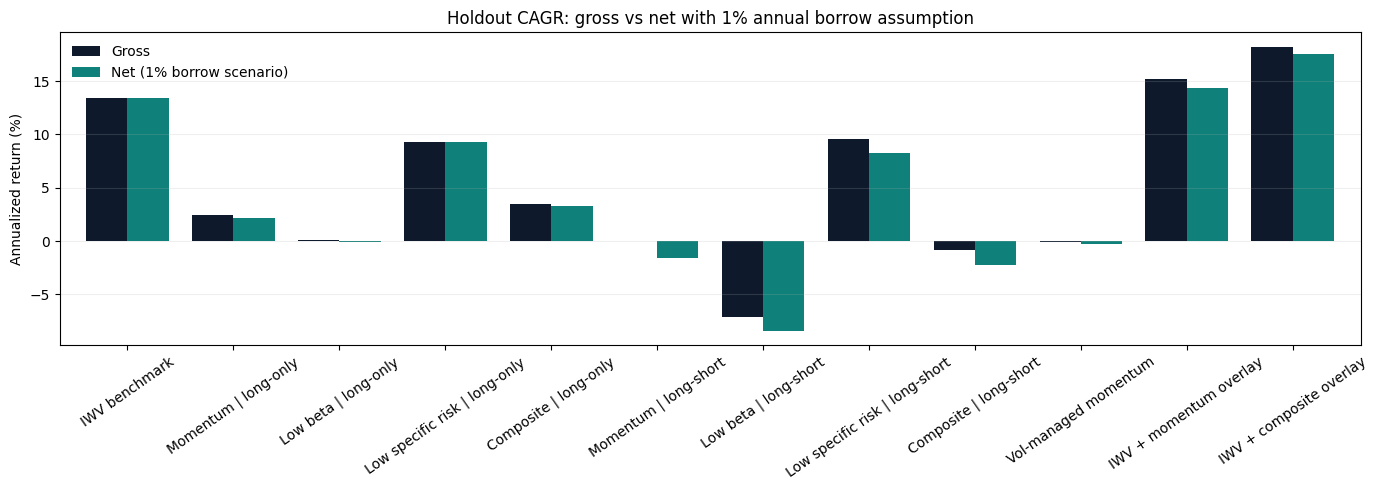

### ETF spread sensitivity (1% annual borrow scenario)

IWV half-spread (bps/traded dollar),0.000000,1.000000,5.000000
Portfolio,,,
IWV + composite overlay,17.57%,17.57%,17.55%
IWV + momentum overlay,14.33%,14.33%,14.31%
IWV benchmark,13.44%,13.44%,13.44%


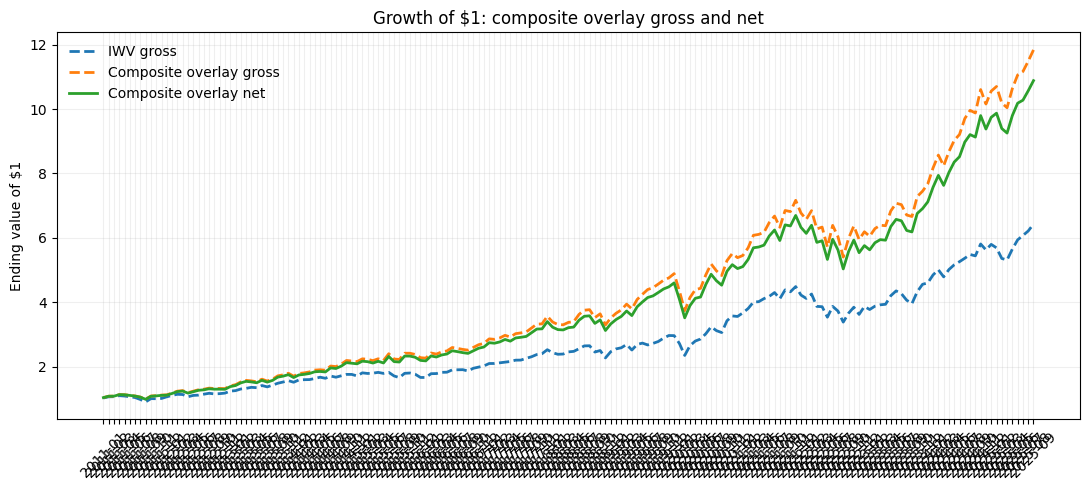

Coverage and exclusions: dated quotes covered 9.5% of composite-overlay stock traded notional; mapped identifiers covered 88.3%. Remaining mapped names use formation-month median half-spreads; unmapped names use the file-wide median fallback (0.060%). Borrow data are absent; 0%, 1%, and 5% annual costs are assumptions on average short exposure, not measured fees. No IWV quote series was identified; its 0/1/5 bp cases are assumptions. Excluded are commissions, impact, recall/availability, financing, taxes, and ETF expense ratios.

CRSP quote rows: 2008379 monthly rows: 2371997 holdout months: 177


In [ ]:
# Gross and net costs for all strategies
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
_holdout_start=pd.Period('2011-01','M'); _full_fallback=float(_full_spread_median) if '_full_spread_median' in globals() else .0006
_vm_mult=(lo['Vol-managed momentum']/lo['Momentum'].replace(0,np.nan)).replace([np.inf,-np.inf],np.nan).interpolate(limit_direction='both').fillna(1.).clip(0,1)
_specs={'IWV benchmark':('iwv',None,None,returns['Russell 3000 proxy (IWV)']),'Momentum | long-only':('stock','Long-only','Momentum',returns['Momentum']),'Low beta | long-only':('stock','Long-only','Low beta',returns['Low beta']),'Low specific risk | long-only':('stock','Long-only','Low specific risk',returns['Low specific risk']),'Composite | long-only':('stock','Long-only','Composite',returns['Composite']),'Momentum | long-short':('stock','Long-short','Momentum',ls['Momentum']),'Low beta | long-short':('stock','Long-short','Low beta',ls['Low beta']),'Low specific risk | long-short':('stock','Long-short','Low specific risk',ls['Low specific risk']),'Composite | long-short':('stock','Long-short','Composite',ls['Composite']),'Vol-managed momentum':('scaled','Long-only','Momentum',returns['Vol-managed momentum']),'IWV + momentum overlay':('overlay','Long-short','Momentum',returns['IWV + MOM overlay']),'IWV + composite overlay':('overlay','Long-short','Composite',returns['IWV + Composite overlay'])}
_cost_diagnostics={}; _net_returns={}
for _label,(_kind,_book,_sig,_gross0) in _specs.items():
 _gross=_gross0.dropna().astype(float).sort_index(); _gross=_gross.loc[_gross.index>=pd.Period('2001-01','M')]; _costs_m={}; _turn_m={}; _direct_m={}; _mapped_m={}; _short_m={}; _etf_m={}
 if _kind in ('stock','scaled','overlay'):
  _sub=crsp_pos.loc[(crsp_pos.book==_book)&(crsp_pos.signal==_sig),['barrid','holding_month','weight','forward_ret','imputed_half_spread','quote_direct','crsp_permno']]; _groups={m:g for m,g in _sub.groupby('holding_month',sort=False)}
 _prev={}; _prev_etf=0.; _prev_g=None; _prev_iwv=None
 for _m in _gross.index:
  _g=float(_gross.loc[_m]); _iwv_r=float(returns['Russell 3000 proxy (IWV)'].get(_m,0.)); _target={}; _mult=1.; _beta=0.
  if _kind in ('stock','scaled','overlay') and _m in _groups:
   if _kind=='scaled': _mult=float(_vm_mult.get(_m,1.))
   if _kind=='overlay': _mult=float(scale[_sig].get(_m,0.)); _beta=float(model_beta[_sig].get(_m,0.))
   for _r in _groups[_m].itertuples(index=False):
    _aid=str(_r.barrid); _ret=float(_r.forward_ret) if pd.notna(_r.forward_ret) else -1.; _sp=float(_r.imputed_half_spread) if pd.notna(_r.imputed_half_spread) else _full_fallback
    _target[_aid]=(float(_r.weight)*_mult,_ret,_sp,bool(_r.quote_direct) if pd.notna(_r.quote_direct) else False,pd.notna(_r.crsp_permno))
  _etf_target=1. if _kind=='iwv' else (1.-_mult*_beta if _kind=='overlay' else 0.); _turn=_direct=_mapped=_scost=0.
  for _aid in set(_target)|set(_prev):
   _cur=_target.get(_aid,(0.,0.,_prev.get(_aid,(0.,_full_fallback,False,False))[1],False,False)); _old=_prev.get(_aid,(0.,_cur[2],False,False)); _d=abs(_cur[0]-_old[0]); _spr=_cur[2] if _aid in _target else _old[1]
   _turn+=_d; _scost+=_d*_spr
   if (_cur[3] if _aid in _target else _old[2]): _direct+=_d
   if (_cur[4] if _aid in _target else _old[3]): _mapped+=_d
  _etf_drift=_prev_etf
  if _prev_g is not None: _etf_drift=_prev_etf*(1.+_prev_iwv)/max(1e-12,1.+_prev_g)
  _etf_trade=abs(_etf_target-_etf_drift); _short_open=sum(-v[0] for v in _target.values() if v[0]<0); _den=max(1e-12,1.+_g); _short_end=sum((-v[0])*max(0.,1.+v[1])/_den for v in _target.values() if v[0]<0)
  _costs_m[_m]=_scost; _turn_m[_m]=_turn; _direct_m[_m]=_direct; _mapped_m[_m]=_mapped; _short_m[_m]=max(0.,(_short_open+_short_end)/2.); _etf_m[_m]=_etf_trade
  _prev={a:(v[0]*(1.+v[1])/_den,v[2],v[3],v[4]) for a,v in _target.items()}; _prev_etf=_etf_target; _prev_g=_g; _prev_iwv=_iwv_r
 _diag=pd.DataFrame(index=_gross.index)
 for _col,_vals in [('stock_spread_cost',_costs_m),('stock_turnover',_turn_m),('direct_traded',_direct_m),('mapped_traded',_mapped_m),('short_exposure',_short_m),('iwv_turnover',_etf_m)]: _diag[_col]=pd.Series(_vals).reindex(_diag.index).fillna(0.)
 _diag['gross']=_gross; _cost_diagnostics[_label]=_diag; _net_returns[_label]={}
 for _br in [0.,.01,.05]: _net_returns[_label][_br]=_gross-_diag.stock_spread_cost-_diag.iwv_turnover*.0001-_diag.short_exposure*_br/12.
def _cagr(_r):
 _r=pd.Series(_r).dropna().astype(float); return -1. if len(_r)==0 or (_r<=-1).any() else float(np.prod(1.+_r)**(12./len(_r))-1.)
_rows=[]
for _label,(_kind,_book,_sig,_gross0) in _specs.items():
 _g=_gross0.dropna().astype(float).sort_index(); _ix=_g.index[_g.index>=_holdout_start]; _g=_g.reindex(_ix); _d=_cost_diagnostics[_label].reindex(_ix).fillna(0.)
 _rows.append({'Portfolio':_label,'Gross CAGR':_cagr(_g),'Net CAGR | 0% borrow':_cagr(_net_returns[_label][0.].reindex(_ix)),'Net CAGR | 1% borrow':_cagr(_net_returns[_label][.01].reindex(_ix)),'Net CAGR | 5% borrow':_cagr(_net_returns[_label][.05].reindex(_ix)),'Gross vol':_g.std(ddof=1)*np.sqrt(12),'Net vol | 1% borrow':_net_returns[_label][.01].reindex(_ix).std(ddof=1)*np.sqrt(12),'Annual one-way turnover':(_d.stock_turnover+_d.iwv_turnover).mean()*12,'Direct-quote share of stock trades':_d.direct_traded.sum()/_d.stock_turnover.sum() if _d.stock_turnover.sum()>0 else np.nan,'Mapped share of stock trades':_d.mapped_traded.sum()/_d.stock_turnover.sum() if _d.stock_turnover.sum()>0 else np.nan,'Stock spread cost (bps/year)':_d.stock_spread_cost.mean()*12*10000,'IWV cost (bps/year; 1bp ETF assumption)':(_d.iwv_turnover*.0001).mean()*12*10000})
_cost_summary=pd.DataFrame(_rows).set_index('Portfolio'); _etf_rows=[]
for _label in ['IWV benchmark','IWV + momentum overlay','IWV + composite overlay']:
 _g=_specs[_label][3].dropna().astype(float).sort_index(); _ix=_g.index[_g.index>=_holdout_start]; _d=_cost_diagnostics[_label].reindex(_ix).fillna(0.)
 for _bp in [0.,1.,5.]: _etf_rows.append({'Portfolio':_label,'IWV half-spread (bps/traded dollar)':_bp,'Borrow rate (annual)':.01,'Net CAGR':_cagr(_g.reindex(_ix)-_d.stock_spread_cost-_d.iwv_turnover*_bp/10000.-_d.short_exposure*.01/12.)})
_etf_sensitivity=pd.DataFrame(_etf_rows); _cols=['Gross CAGR','Net CAGR | 0% borrow','Net CAGR | 1% borrow','Net CAGR | 5% borrow','Gross vol','Net vol | 1% borrow','Annual one-way turnover','Direct-quote share of stock trades','Stock spread cost (bps/year)','IWV cost (bps/year; 1bp ETF assumption)']
_fmt={c:'{:.2%}' for c in ['Gross CAGR','Net CAGR | 0% borrow','Net CAGR | 1% borrow','Net CAGR | 5% borrow','Gross vol','Net vol | 1% borrow','Direct-quote share of stock trades']}; _fmt.update({'Annual one-way turnover':'{:.2f}x','Stock spread cost (bps/year)':'{:.1f}','IWV cost (bps/year; 1bp ETF assumption)':'{:.2f}'})
display(Markdown('## Gross and cost-adjusted holdout results (Jan 2011–Sep 2025)')); display(Markdown('Stock costs use CRSP relative half-spreads where available and monthly or file-wide medians otherwise. Monthly trades compare target weights with prior holdings drifted by supplied returns. IWV quotes are absent; ETF costs assume 1 bp per traded dollar, with sensitivity below.'))
display(_cost_summary[_cols].style.format(_fmt)); _ax=_cost_summary[['Gross CAGR','Net CAGR | 1% borrow']].mul(100).plot(kind='bar',figsize=(14,5),color=['#0E1A2B','#0F817A'],width=.78); _ax.set_title('Holdout CAGR: gross vs net with 1% annual borrow assumption'); _ax.set_ylabel('Annualized return (%)'); _ax.set_xlabel(''); _ax.legend(['Gross','Net (1% borrow scenario)'],frameon=False); _ax.tick_params(axis='x',rotation=35); _ax.grid(axis='y',alpha=.2); plt.tight_layout(); plt.show()
display(Markdown('### ETF spread sensitivity (1% annual borrow scenario)')); display(_etf_sensitivity.pivot(index='Portfolio',columns='IWV half-spread (bps/traded dollar)',values='Net CAGR').style.format('{:.2%}'))
_ix=returns.index[returns.index>=_holdout_start]; _fig,_ax=plt.subplots(figsize=(11,5))
for _name,_series,_style in [('IWV gross',returns['Russell 3000 proxy (IWV)'],'--'),('Composite overlay gross',returns['IWV + Composite overlay'],'--'),('Composite overlay net',_net_returns['IWV + composite overlay'][.01],'-')]:
 _r=_series.reindex(_ix).fillna(0.); _ax.plot(_r.index.astype(str),(1.+_r).cumprod(),label=_name,linestyle=_style,linewidth=2)
_ax.set_title('Growth of $1: composite overlay gross and net'); _ax.set_ylabel('Ending value of $1'); _ax.set_xlabel(''); _ax.legend(frameon=False); _ax.grid(alpha=.2); _ax.tick_params(axis='x',rotation=45); plt.tight_layout(); plt.show()
_dir=_cost_summary.loc['IWV + composite overlay','Direct-quote share of stock trades']; _map=_cost_summary.loc['IWV + composite overlay','Mapped share of stock trades']; display(Markdown(f'Coverage and exclusions: dated quotes covered {_dir:.1%} of composite-overlay stock traded notional; mapped identifiers covered {_map:.1%}. Remaining mapped names use formation-month median half-spreads; unmapped names use the file-wide median fallback ({_full_fallback:.3%}). Borrow data are absent; 0%, 1%, and 5% annual costs are assumptions on average short exposure, not measured fees. No IWV quote series was identified; its 0/1/5 bp cases are assumptions. Excluded are commissions, impact, recall/availability, financing, taxes, and ETF expense ratios.'))
print('CRSP quote rows:',len(crsp_q),'monthly rows:',len(crsp_m),'holdout months:',len(returns.loc[returns.index>=_holdout_start]))

In [ ]:
from IPython.display import display, Markdown
def _cg(r):
 r=pd.Series(r).dropna().astype(float); return -1. if len(r)==0 or (r<=-1).any() else float(np.prod(1+r)**(12/len(r))-1)
def _cum(r):
 r=pd.Series(r).dropna().astype(float); return -1. if len(r)==0 else float(np.prod(1+r)-1)
def _dd(r):
 w=(1+pd.Series(r).dropna().astype(float)).cumprod(); return float((w/w.cummax()-1).min()) if len(w) else np.nan
_dev=[]
for lab,(_,_,_,g0) in _specs.items():
 g=g0.loc[(g0.index>=pd.Period('2001-01','M'))&(g0.index<=pd.Period('2010-12','M'))].dropna(); _dev.append({'Portfolio':lab,'Months':len(g),'Gross CAGR':_cg(g),'Net CAGR 0% borrow':_cg(_net_returns[lab][0.].reindex(g.index)),'Net CAGR 1% borrow':_cg(_net_returns[lab][.01].reindex(g.index)),'Net CAGR 5% borrow':_cg(_net_returns[lab][.05].reindex(g.index))})
_dev_table=pd.DataFrame(_dev).set_index('Portfolio'); display(Markdown('## Development-period cost check (2001–2010)')); display(_dev_table.style.format('{:.2%}',subset=['Gross CAGR','Net CAGR 0% borrow','Net CAGR 1% borrow','Net CAGR 5% borrow']))
_windows={'Financial crisis':('2007-10','2009-03'),'COVID selloff':('2020-02','2020-04'),'2022 calendar year':('2022-01','2022-12')}; _stress=[]
for wn,(a,b) in _windows.items():
 a,b=pd.Period(a,'M'),pd.Period(b,'M')
 for lab,(_,_,_,g0) in _specs.items():
  g=g0.loc[(g0.index>=a)&(g0.index<=b)].dropna(); net=_net_returns[lab][.01].reindex(g.index); _stress.append({'Window':wn,'Portfolio':lab,'Months':len(g),'Gross return':_cum(g),'Net return 1% borrow':_cum(net),'Net max drawdown 1% borrow':_dd(net)})
_stress_table=pd.DataFrame(_stress); display(Markdown('## Stress windows: gross and net (1% annual borrow scenario)')); display(_stress_table.style.format({'Gross return':'{:.2%}','Net return 1% borrow':'{:.2%}','Net max drawdown 1% borrow':'{:.2%}'}))
_year=[]
for lab in ['IWV benchmark','IWV + momentum overlay','IWV + composite overlay']:
 g0=_specs[lab][3]
 for yr in range(2011,2026):
  ix=g0.index[(g0.index.year==yr)&(g0.index>=_holdout_start)]
  if len(ix): _year.append({'Year':yr,'Portfolio':lab,'Months':len(ix),'Gross return':_cum(g0.reindex(ix)),'Net return 0% borrow':_cum(_net_returns[lab][0.].reindex(ix)),'Net return 1% borrow':_cum(_net_returns[lab][.01].reindex(ix)),'Net return 5% borrow':_cum(_net_returns[lab][.05].reindex(ix))})
_year_table=pd.DataFrame(_year); display(Markdown('## Calendar-year gross and net returns (IWV and overlays)')); display(_year_table.style.format({'Gross return':'{:.2%}','Net return 0% borrow':'{:.2%}','Net return 1% borrow':'{:.2%}','Net return 5% borrow':'{:.2%}'}))

## Development-period cost check (2001–2010)

,Months,Gross CAGR,Net CAGR 0% borrow,Net CAGR 1% borrow,Net CAGR 5% borrow
Portfolio,,,,,
IWV benchmark,120,2.07%,2.07%,2.07%,2.07%
Momentum | long-only,120,-2.80%,-3.83%,-3.83%,-3.83%
Low beta | long-only,120,-2.23%,-2.72%,-2.72%,-2.72%
Low specific risk | long-only,120,4.50%,4.19%,4.19%,4.19%
Composite | long-only,120,-0.22%,-0.78%,-0.78%,-0.78%
Momentum | long-short,120,-1.45%,-3.78%,-4.75%,-8.55%
Low beta | long-short,120,-4.44%,-5.84%,-6.80%,-10.53%
Low specific risk | long-short,120,9.19%,7.94%,6.87%,2.68%
Composite | long-short,120,0.36%,-1.32%,-2.32%,-6.21%


## Stress windows: gross and net (1% annual borrow scenario)

,Window,Portfolio,Months,Gross return,Net return 1% borrow,Net max drawdown 1% borrow
0,Financial crisis,IWV benchmark,18,-46.23%,-46.23%,-51.23%
1,Financial crisis,Momentum | long-only,18,-56.64%,-57.04%,-60.23%
2,Financial crisis,Low beta | long-only,18,-48.32%,-48.63%,-51.10%
3,Financial crisis,Low specific risk | long-only,18,-45.00%,-45.18%,-48.67%
4,Financial crisis,Composite | long-only,18,-48.48%,-48.76%,-51.78%
5,Financial crisis,Momentum | long-short,18,2.74%,-0.74%,-13.54%
6,Financial crisis,Low beta | long-short,18,28.38%,24.58%,-6.89%
7,Financial crisis,Low specific risk | long-short,18,36.11%,32.75%,-4.89%
8,Financial crisis,Composite | long-short,18,29.66%,25.97%,-8.12%
9,Financial crisis,Vol-managed momentum,18,-42.31%,-42.67%,-45.29%


## Calendar-year gross and net returns (IWV and overlays)

,Year,Portfolio,Months,Gross return,Net return 0% borrow,Net return 1% borrow,Net return 5% borrow
0,2011,IWV benchmark,12,0.78%,0.78%,0.78%,0.78%
1,2012,IWV benchmark,12,16.43%,16.43%,16.43%,16.43%
2,2013,IWV benchmark,12,33.01%,33.01%,33.01%,33.01%
3,2014,IWV benchmark,12,12.39%,12.39%,12.39%,12.39%
4,2015,IWV benchmark,12,0.33%,0.33%,0.33%,0.33%
5,2016,IWV benchmark,12,12.63%,12.63%,12.63%,12.63%
6,2017,IWV benchmark,12,20.97%,20.97%,20.97%,20.97%
7,2018,IWV benchmark,12,-5.44%,-5.44%,-5.44%,-5.44%
8,2019,IWV benchmark,12,30.66%,30.66%,30.66%,30.66%
9,2020,IWV benchmark,12,20.55%,20.55%,20.55%,20.55%


In [ ]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd

display(Markdown("""
## Missing-return assumption sensitivity

The **−100% treatment remains the primary baseline**. These cases rescore the holdings already selected at formation; next-month missingness does not change selection. The zero-return case assigns 0% to missing outcomes. The exclude-and-reweight case is a **diagnostic only** because dropping missing outcomes can create survivorship bias. It reweights within each long-only book or separately within each long and short side. If an entire long-short side has no observed outcomes, that month's diagnostic return is left unavailable.

The overlay uses the existing baseline scale so the comparison isolates the missing-return assumption. Metrics are gross, matching the main performance table.
"""))

# Use the same holdout months as the existing performance table.
_sens_months = returns.index[
    (returns.index >= TEST_START) & (returns.index <= LAST_COMPLETE_MONTH)
].sort_values()
assert _sens_months.is_unique and _sens_months.is_monotonic_increasing

_iwv = returns["Russell 3000 proxy (IWV)"].reindex(_sens_months).astype(float)
_scale = scale["Composite"].reindex(_sens_months).astype(float).fillna(0.0)

# These are the fixed holdings selected by the Composite signal for each holdout month.
_pos = positions.loc[
    positions["signal"].eq("Composite")
    & positions["holding_month"].isin(_sens_months)
].copy()
_pos["missing_forward"] = _pos["missing_forward"].fillna(False).astype(bool)
_pos["side"] = np.where(_pos["weight"].lt(0), "Short", "Long")

def _build_missing_case(case):
    """Score fixed holdings under one missing-return assumption."""
    q = _pos.copy()
    q["case_return"] = q["forward_ret"].astype(float)

    if case == "baseline":
        q.loc[q["missing_forward"], "case_return"] = -1.0
    elif case == "zero":
        q.loc[q["missing_forward"], "case_return"] = 0.0
    elif case == "exclude":
        q = q.loc[~q["missing_forward"]].copy()
        keys = ["holding_month", "book", "side"]
        side_gross = q.groupby(keys, observed=True)["weight"].transform(
            lambda w: w.abs().sum()
        )
        q["case_weight"] = q["weight"].astype(float) / side_gross
    else:
        raise ValueError(f"Unknown case: {case}")

    if case != "exclude":
        q["case_weight"] = q["weight"].astype(float)

    # Check the notebook's +1 long / -1 short side weight convention.
    side_sums = q.groupby(
        ["holding_month", "book", "side"], observed=True
    )["case_weight"].sum()
    targets = np.where(
        side_sums.index.get_level_values("side").eq("Short"), -1.0, 1.0
    )
    assert np.allclose(side_sums.to_numpy(), targets, atol=1e-10)

    q["case_pnl"] = q["case_weight"] * q["case_return"]
    q["case_beta"] = q["case_weight"] * q["beta"].astype(float)

    lo = (
        q.loc[q["book"].eq("Long-only")]
        .groupby("holding_month", observed=True)["case_pnl"]
        .sum()
        .reindex(_sens_months)
    )

    ls_q = q.loc[q["book"].eq("Long-short")]
    ls_ret = (
        ls_q.groupby("holding_month", observed=True)["case_pnl"]
        .sum()
        .reindex(_sens_months)
    )
    beta = (
        ls_q.groupby("holding_month", observed=True)["case_beta"]
        .sum()
        .reindex(_sens_months)
    )

    if case == "exclude":
        kept_sides = (
            ls_q.groupby("holding_month", observed=True)["side"]
            .nunique()
            .reindex(_sens_months, fill_value=0)
        )
        expected_sides = (
            _pos.loc[_pos["book"].eq("Long-short")]
            .groupby("holding_month", observed=True)["side"]
            .nunique()
            .reindex(_sens_months, fill_value=0)
        )
        valid_month = kept_sides.eq(expected_sides)
        ls_ret = ls_ret.where(valid_month)
        beta = beta.where(valid_month)

    return lo.astype(float), ls_ret.astype(float), beta.astype(float)

def _assert_same_monthly_series(actual, expected, label):
    actual = pd.Series(actual).reindex(_sens_months).astype(float)
    expected = pd.Series(expected).reindex(_sens_months).astype(float)
    assert actual.index.equals(expected.index), f"{label}: month indexes differ"
    assert np.allclose(
        actual.to_numpy(), expected.to_numpy(),
        rtol=1e-10, atol=1e-10, equal_nan=True
    ), f"{label}: baseline does not reproduce the existing series"

# Verify that the baseline matches the existing portfolio calculations.
_base_lo, _base_ls, _base_beta = _build_missing_case("baseline")
_assert_same_monthly_series(_base_lo, returns["Composite"], "Composite long-only")
_assert_same_monthly_series(_base_ls, ls["Composite"], "Composite long-short")
_assert_same_monthly_series(_base_beta, model_beta["Composite"], "Composite beta")

def _overlay_return(ls_return, beta_return):
    active_return = ls_return.reindex(_sens_months) - (
        beta_return.reindex(_sens_months) * _iwv
    )
    return _iwv + active_return * _scale

_base_overlay = _overlay_return(_base_ls, _base_beta)
_assert_same_monthly_series(
    _base_overlay, returns["IWV + Composite overlay"], "Composite overlay"
)

_zero_lo, _zero_ls, _zero_beta = _build_missing_case("zero")
_zero_overlay = _overlay_return(_zero_ls, _zero_beta)

_excl_lo, _excl_ls, _excl_beta = _build_missing_case("exclude")
_excl_overlay = _overlay_return(_excl_ls, _excl_beta)

_case_series = {
    "Baseline: missing = −100%": {
        "IWV benchmark": _iwv,
        "Composite | long-only": _base_lo,
        "IWV + Composite overlay": _base_overlay,
    },
    "Zero-return assumption": {
        "IWV benchmark": _iwv,
        "Composite | long-only": _zero_lo,
        "IWV + Composite overlay": _zero_overlay,
    },
    "Exclude-and-reweight diagnostic": {
        "IWV benchmark": _iwv,
        "Composite | long-only": _excl_lo,
        "IWV + Composite overlay": _excl_overlay,
    },
}

_metric_rows = []
for case_name, portfolios in _case_series.items():
    for portfolio_name, portfolio_return in portfolios.items():
        row = stats(portfolio_return, _iwv)
        row.update({"Case": case_name, "Portfolio": portfolio_name})
        _metric_rows.append(row)

_sens_metrics = pd.DataFrame(_metric_rows).set_index(["Case", "Portfolio"])
_baseline_metrics = _sens_metrics.xs(
    "Baseline: missing = −100%", level="Case"
)

for metric in _baseline_metrics.columns:
    _sens_metrics[f"Δ {metric} vs baseline"] = [
        (
            row[metric] - _baseline_metrics.loc[portfolio, metric]
            if pd.notna(row[metric])
            and pd.notna(_baseline_metrics.loc[portfolio, metric])
            else np.nan
        )
        for (case, portfolio), row in _sens_metrics.iterrows()
    ]

_formats = {
    "Months": "{:.0f}",
    "Δ Months vs baseline": "{:+.0f}",
}
for col in _sens_metrics.columns:
    if col in ["CAGR", "Volatility", "Max drawdown", "Active CAGR", "Tracking error"]:
        _formats[col] = "{:+.2%}" if col == "Active CAGR" else "{:.2%}"
    elif col.startswith("Δ ") and any(
        metric in col for metric in
        ["CAGR", "Volatility", "Max drawdown", "Active CAGR", "Tracking error"]
    ):
        _formats[col] = "{:+.2%}"
    elif col in ["Sharpe (rf=0)", "Beta", "Information ratio"]:
        _formats[col] = "{:.2f}"
    elif col.startswith("Δ "):
        _formats[col] = "{:+.2f}"

display(Markdown("### Composite and IWV holdout performance by case"))
display(_sens_metrics.style.format(_formats))

# Missing-outcome counts and absolute-weight shares for the Composite holdings.
_cov = _pos.copy()
_cov["abs_weight"] = _cov["weight"].astype(float).abs()
_cov["missing_abs_weight"] = _cov["abs_weight"].where(
    _cov["missing_forward"], 0.0
)

_cov_month = _cov.groupby(
    ["holding_month", "book", "side"], observed=True, sort=True
).agg(
    selected_holdings=("barrid", "size"),
    missing_holdings=("missing_forward", "sum"),
    missing_abs_weight=("missing_abs_weight", "sum"),
    total_abs_weight=("abs_weight", "sum"),
)
_cov_month["missing_weight_share"] = (
    _cov_month["missing_abs_weight"] / _cov_month["total_abs_weight"]
)
_cov_month.index.names = ["Holding month", "Book", "Side"]

display(Markdown(
    "### Composite missing returns by month\n\n"
    "Weight share is based on absolute weights. Long and short sides are reported separately."
))
display(_cov_month.style.format({
    "selected_holdings": "{:.0f}",
    "missing_holdings": "{:.0f}",
    "missing_abs_weight": "{:.3f}",
    "total_abs_weight": "{:.3f}",
    "missing_weight_share": "{:.2%}",
}))

_cov_overall = _cov.groupby(["book", "side"], observed=True, sort=True).agg(
    holdout_months=("holding_month", "nunique"),
    selected_position_months=("barrid", "size"),
    missing_position_months=("missing_forward", "sum"),
    missing_abs_weight=("missing_abs_weight", "sum"),
    total_abs_weight=("abs_weight", "sum"),
)
_cov_overall["missing_outcome_rate"] = (
    _cov_overall["missing_position_months"]
    / _cov_overall["selected_position_months"]
)
_cov_overall["missing_weight_share"] = (
    _cov_overall["missing_abs_weight"] / _cov_overall["total_abs_weight"]
)

display(Markdown("### Composite missing returns overall"))
display(_cov_overall.style.format({
    "holdout_months": "{:.0f}",
    "selected_position_months": "{:.0f}",
    "missing_position_months": "{:.0f}",
    "missing_abs_weight": "{:.3f}",
    "total_abs_weight": "{:.3f}",
    "missing_outcome_rate": "{:.2%}",
    "missing_weight_share": "{:.2%}",
}))

print(
    "Checks passed: baseline series reproduce the notebook's existing results; "
    "long/short weights keep the +1/−1 convention; scenario returns share the "
    "same holdout month index."
)


## Missing-return assumption sensitivity

The **−100% treatment remains the primary baseline**. These cases rescore the holdings already selected at formation; next-month missingness does not change selection. The zero-return case assigns 0% to missing outcomes. The exclude-and-reweight case is a **diagnostic only** because dropping missing outcomes can create survivorship bias. It reweights within each long-only book or separately within each long and short side. If an entire long-short side has no observed outcomes, that month's diagnostic return is left unavailable.

The overlay uses the existing baseline scale so the comparison isolates the missing-return assumption. Metrics are gross, matching the main performance table.


NameError: name 'returns' is not defined